### Laboratorium 4, cześć 2: Transformacja Hougha

#### _Fabuła_
_Budujemy aplikację do szkolenia snookerzystów. Jej celem będzie, między innymi, analiza pozycji i sugerowanie zagrań. Naturalnie, podstawą działania aplikacji musi być funkcjonalność detekcji bil i określenia ich pozycji w układzie współrzędnych stołu. W dalszych etapach określane będą geometryczne relacje między bilami i łuzami - ich implementacją zajmie się jednak inny zespół._

#### Zadanie
Twoim celem będzie wykonanie detekcji **bil** oraz **band** za pomocą transformacji Hougha.
Przygotujesz potok przetwarzania przyjmujący obraz kolorowy w przestrzeni BGR/RGB a zwracający dwie kolekcje: jedną reprezentującą okręgi (bile), drugą - linie/odcinki (bandy) lub punkty (narożniki stołu).
Format tych kolekcji jest dowolny, szczegóły implementacji potoku podobnie.
W ogólności, potok powinien składać się z:
* etapu przetwarzania wstępnego - skorzystaj ze swojego ulubionego detektora krawędzi,
* wykonania transformacji Hougha dla linii ([`cv2.HoughLines`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga0b7ee275f89bb1a799ab70a42131f39d)) do wykrycia band,
* wykonania transformacji Hougha dla okręgów ([`cv2.HoughCircles`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga47849c3be0d0406ad3ca45db65a25d2d)) do wykrycia bil,
* przetwarzania końcowego wyników transformacji (np. usunięcie nadmiarowych/fałszywych detekcji).

Zaimplementuj również funkcję prezentującą wyniki w formie wizualnej, tj. rysującej wykryte obiekty na kopii obrazu wejściowego.

Dane są cztery obrazy.
Staraj się prowadzić eksperymenty na jednym czy dwóch, a następnie zaprezentować wyniki na pozostałych.

#### Oczekiwane rezultaty
1. Zacznij od znalezienia odpowiednich parametrów detektora krawędzi - jeśli na tym etapie wyniki będą słabe, to dalej będzie tylko gorzej (_garbage-in, garbage-out_). Nie skupiaj się na badaniu ich wpływu na wyniki końcowe, a jedynie przedstaw efekt przetwarzania wstępnego, tj. jak wygląda obraz, na którym wykonywana będzie TH. Ta część zadania będzie oceniana binarnie: dobrze/źle.
2. Kalibracja parametrów transformacji Hougha: zadanie **NIE** polega na zrobieniu grid searchu po parametrach TH (wykonanie go nie jest _zabronione_, po prostu nie umieszczaj go w notatniku). Interesujące jest jedynie zrozumienie działania poszczególnych parametrów i ich wpływu na wyniki - pozostaw w notatniku jedynie kilka przykładowych wyników, takich które ilustrują dokonane przez Ciebie wybory parametrów (_ustawiam parametr $x$ na wartość $x_0$, bo przy wartości $x_1$ działo się tak a tak_).
3. Demonstracja wyników na pozostałych obrazach: przedstaw obraz wejściowy, wykryte krawędzie, wykryte obiekty. Efektem powinny być 4 (lub 6) linii reprezentujących bandy, oraz zbiór okręgów odpowiadających bilom (w idealnym przypadku 1:1, ale nie musisz poświęcać długich godzin na wyeliminowaniu _wszystkich_ błędów, ważniejsze jest by umieć wyjaśnić, skąd się wzięły).


#### Literatura
1. Dokumentacja funkcji([`cv2.HoughLines`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga0b7ee275f89bb1a799ab70a42131f39d)) i ([`cv2.HoughCircles`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga47849c3be0d0406ad3ca45db65a25d2d)) - działanie parametrów jest bardzo dobrze opisane.
2. Jeśli chcesz poznać TH "od środka" - [tutaj](https://medium.com/@alb.formaggio/implementing-the-hough-transform-from-scratch-09a56ba7316b) ktoś zaimplementował ją od zera. Czytając, uważaj tylko, by nie powtórzyć po Alberto jego błędu (krawędzie!)
3. Źródło danych do zadania: kompilacja [TOP 40 SHOTS of 2025 British Open](https://www.youtube.com/watch?v=5oZ3fIF9qog) autorstwa GTKomissaRa.

In [45]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown, Checkbox

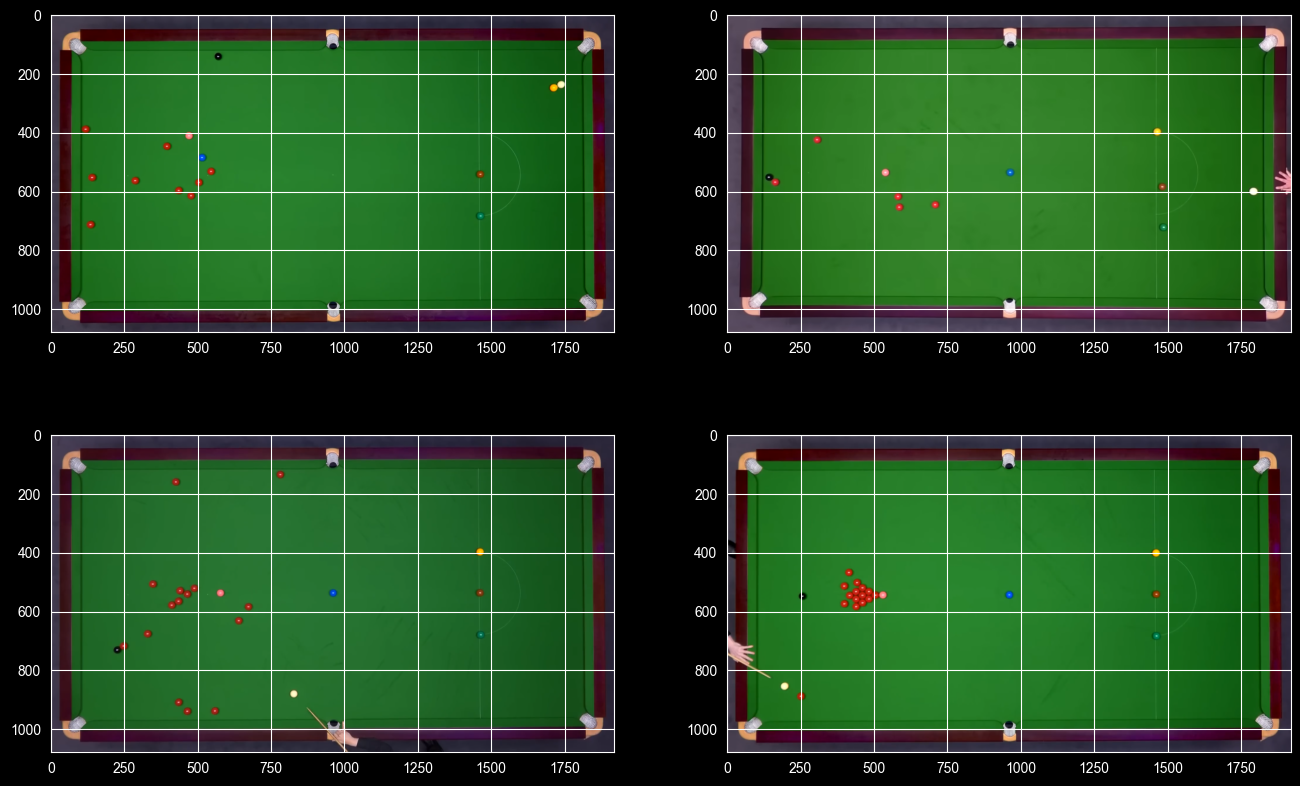

In [2]:
# zbiór danych
mcgill = cv2.imread('Lab4_dane/mcgill.png')
trump = cv2.imread('Lab4_dane/trump.png')
zhao = cv2.imread('Lab4_dane/zhao.png')
mcgill2 = cv2.imread('Lab4_dane/mcgill2.png')
# tu wyświetlone są wszystkie naraz w pomniejszeniu
# w eksperymentach staraj się wyświetlać je w dużym rozmiarze (albo używaj RoI)
_, axes = plt.subplots(2, 2, figsize=(16,10))
axes.ravel()[0].imshow(mcgill[..., ::-1])
axes.ravel()[1].imshow(trump[..., ::-1])
axes.ravel()[2].imshow(zhao[..., ::-1])
axes.ravel()[3].imshow(mcgill2[..., ::-1])

In [21]:
# Draw the lines represented in the hough accumulator on the original image
def drawhoughLinesOnImage(image, houghLines):
    L = max(image.shape)  # linia przez cały obraz, niezależnie od rozdzielczości
    for line in houghLines:
        for rho, theta in line:
            a = np.cos(theta)
            b = np.sin(theta)
            x0 = a*rho
            y0 = b*rho
            x1 = int(x0 + L*(-b))
            y1 = int(y0 + L*(a))
            x2 = int(x0 - L*(-b))
            y2 = int(y0 - L*(a))
            cv2.line(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

# Different weights are added to the image to give a feeling of blending
def blend_images(image, final_image, alpha=0.7, beta=1., gamma=0.):
    return cv2.addWeighted(final_image, alpha, image, beta, gamma)

def preprocess(image):
    # kanał G zamiast szarości: sukno jest jasne, czerwone bile i bandy wyraźnie ciemniejsze
    gray_image = image[:, :, 1]
    blurredImage = cv2.medianBlur(gray_image, 3)
    edgeImage = cv2.Canny(blurredImage, 20, 70)
    return gray_image, blurredImage, edgeImage

def show_preprocessing(image, gray_image, blurredImage, edgeImage, name):
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(20, 12))
    axes[0, 0].imshow(image[..., ::-1])
    axes[0, 0].set_title(f'{name}: Original Image')
    axes[0, 1].imshow(gray_image, cmap='gray')
    axes[0, 1].set_title(f'{name}: Grayscale')
    axes[1, 0].imshow(blurredImage, cmap='gray')
    axes[1, 0].set_title(f'{name}: Median Blur (3x3)')
    axes[1, 1].imshow(edgeImage, cmap='gray')
    axes[1, 1].set_title(f'{name}: Canny (20, 70)')
    for ax in axes.ravel():
        ax.axis('off')
    plt.tight_layout()
    plt.show()

def detect_lines_and_show(image, edgeImage, name):
    # Detect points that form a line
    dis_reso = 1           # Distance resolution in pixels of the Hough grid
    theta = np.pi / 180    # Angular resolution in radians of the Hough grid
    threshold = 170        # minimum no of votes

    houghLines = cv2.HoughLines(edgeImage, dis_reso, theta, threshold)

    houghLinesImage = np.zeros_like(image)  # create an empty image
    if houghLines is not None:
        drawhoughLinesOnImage(houghLinesImage, houghLines)
    orginalImageWithHoughLines = blend_images(houghLinesImage, image)

    n = 0 if houghLines is None else len(houghLines)
    plt.figure(figsize=(16, 10))
    plt.imshow(orginalImageWithHoughLines[..., ::-1])
    plt.title(f'{name}: Original Image with Hough lines ({n})')
    plt.axis('off')
    plt.show()
    return houghLines

In [19]:
images = {'zhao': zhao, 'mcgill2': mcgill2}

def get_channel(img, channel):
    if channel == 'gray':
        return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return img[:, :, {'B': 0, 'G': 1, 'R': 2}[channel]]   # cv2.imread -> BGR

def interactive_canny(name='zhao', channel='G', blur='median', ksize=5, low=20, high=60):
    img = images[name]
    ch = get_channel(img, channel)

    if blur == 'median':
        blurred = cv2.medianBlur(ch, ksize)
    elif blur == 'gauss':
        blurred = cv2.GaussianBlur(ch, (ksize, ksize), 0)
    else:
        blurred = ch

    edges = cv2.Canny(blurred, low, high)

    fig, ax = plt.subplots(1, 2, figsize=(20, 7))
    ax[0].imshow(blurred, cmap='gray')
    ax[0].set_title(f'{name}: kanał {channel}, blur={blur}, k={ksize}')
    ax[1].imshow(edges, cmap='gray')
    ax[1].set_title(f'Canny({low}, {high}) | pikseli krawędzi: {np.count_nonzero(edges)}')
    for a in ax: a.axis('off')
    plt.tight_layout()
    plt.show()

In [17]:
interact(interactive_canny,
         name=Dropdown(options=list(images), value='zhao'),
         channel=Dropdown(options=['gray', 'B', 'G', 'R'], value='G'),
         blur=Dropdown(options=['median', 'gauss', 'none'], value='median'),
         ksize=IntSlider(min=1, max=11, step=1, value=3),
         low=IntSlider(min=0, max=255, step=2, value=20),
         high=IntSlider(min=0, max=255, step=2, value=70));

interactive(children=(Dropdown(description='name', options=('zhao', 'mcgill2'), value='zhao'), Dropdown(descri…

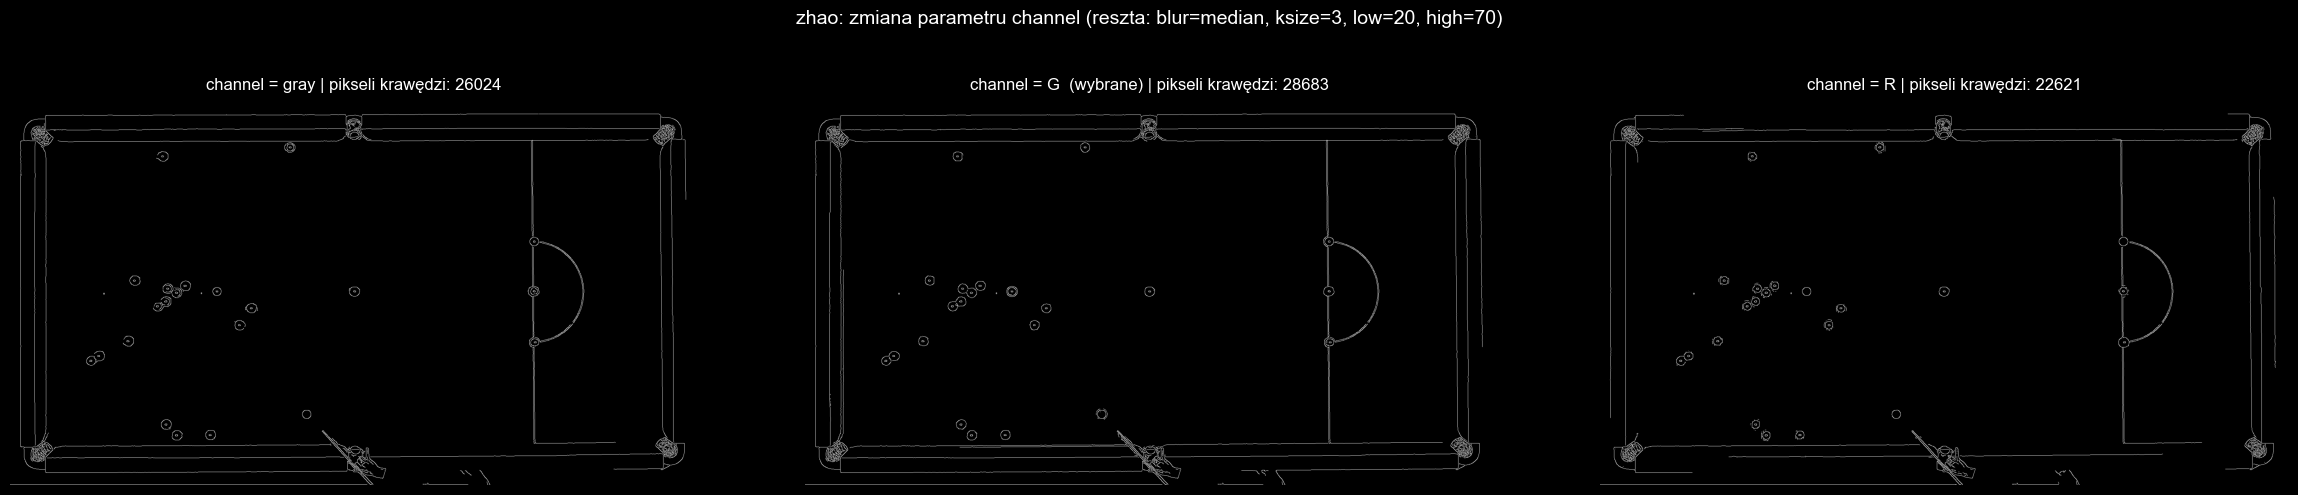

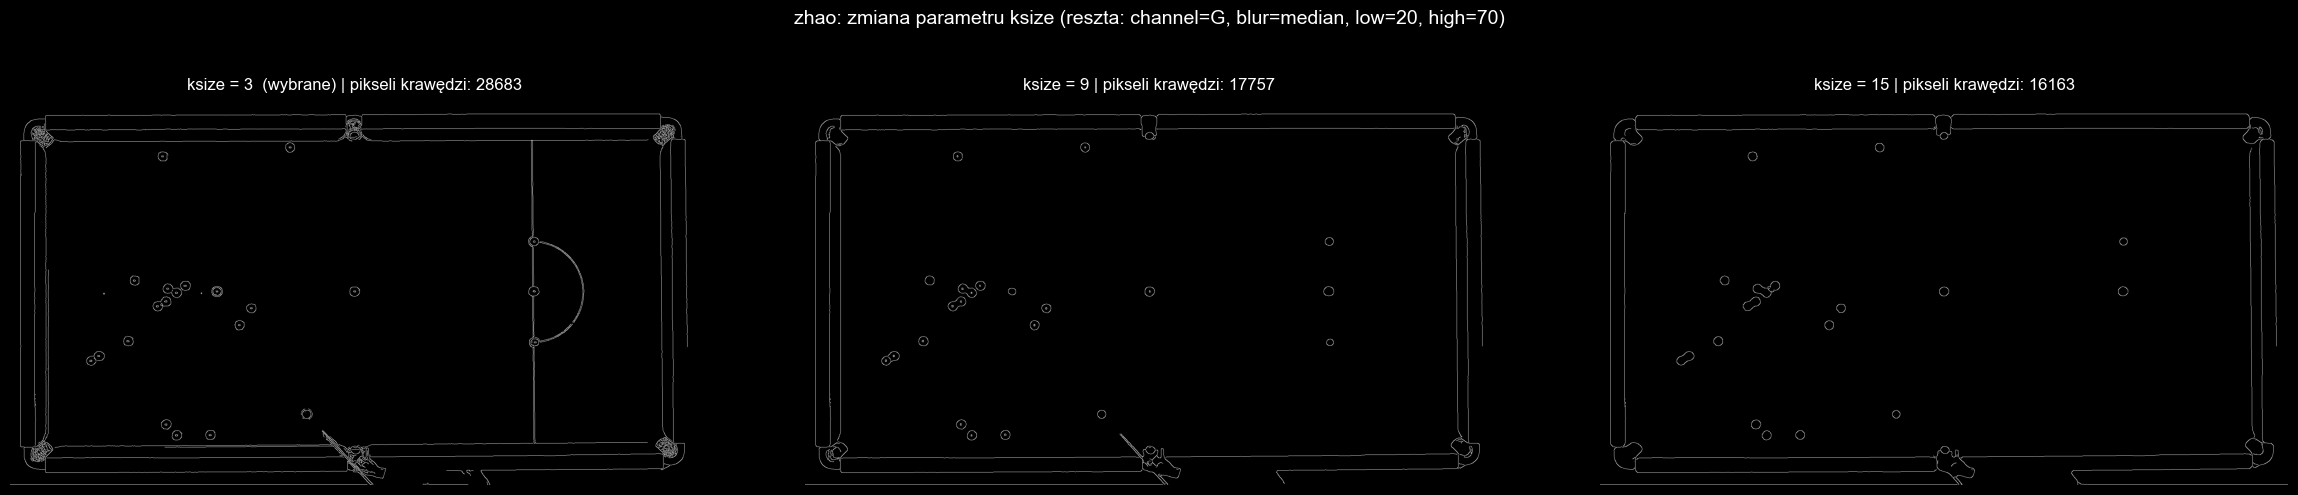

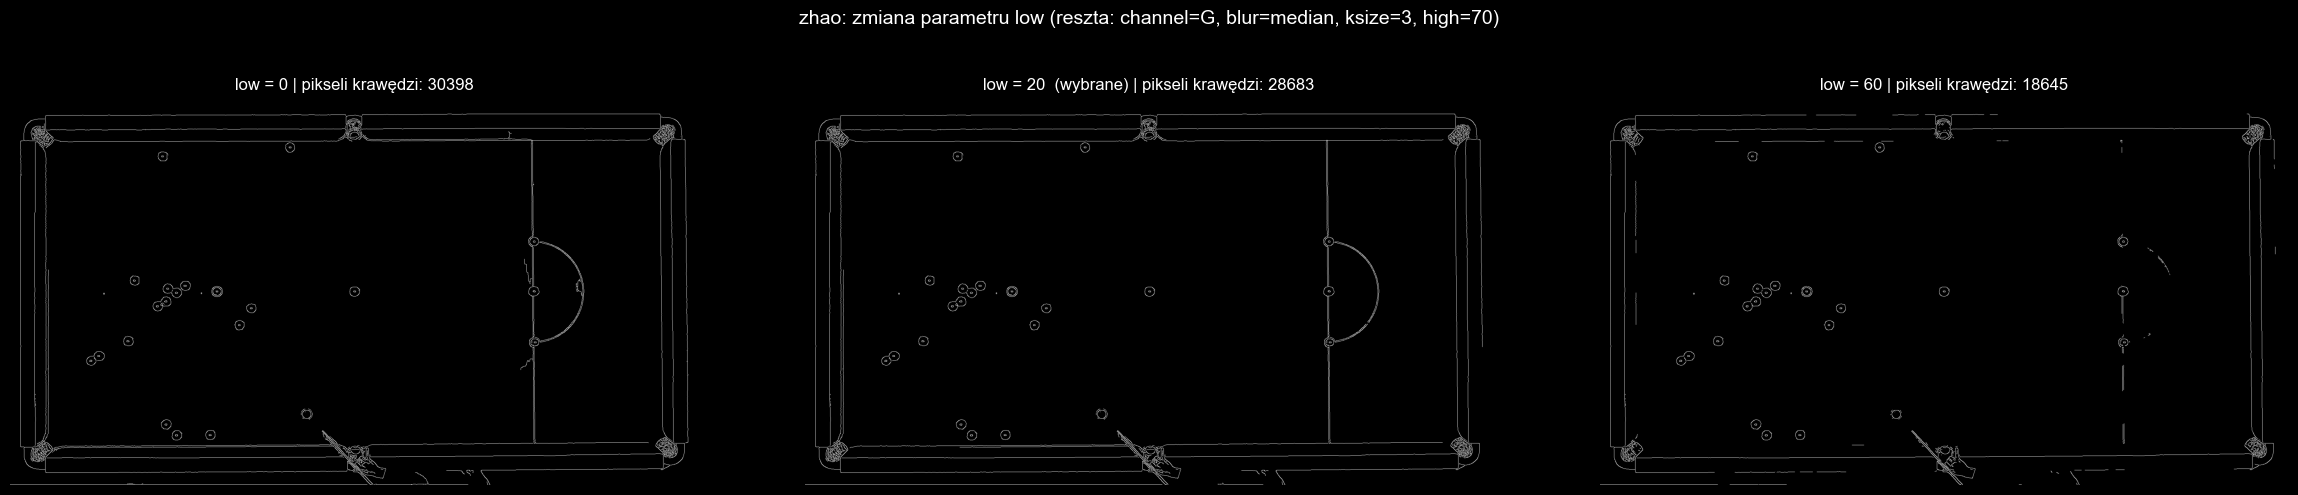

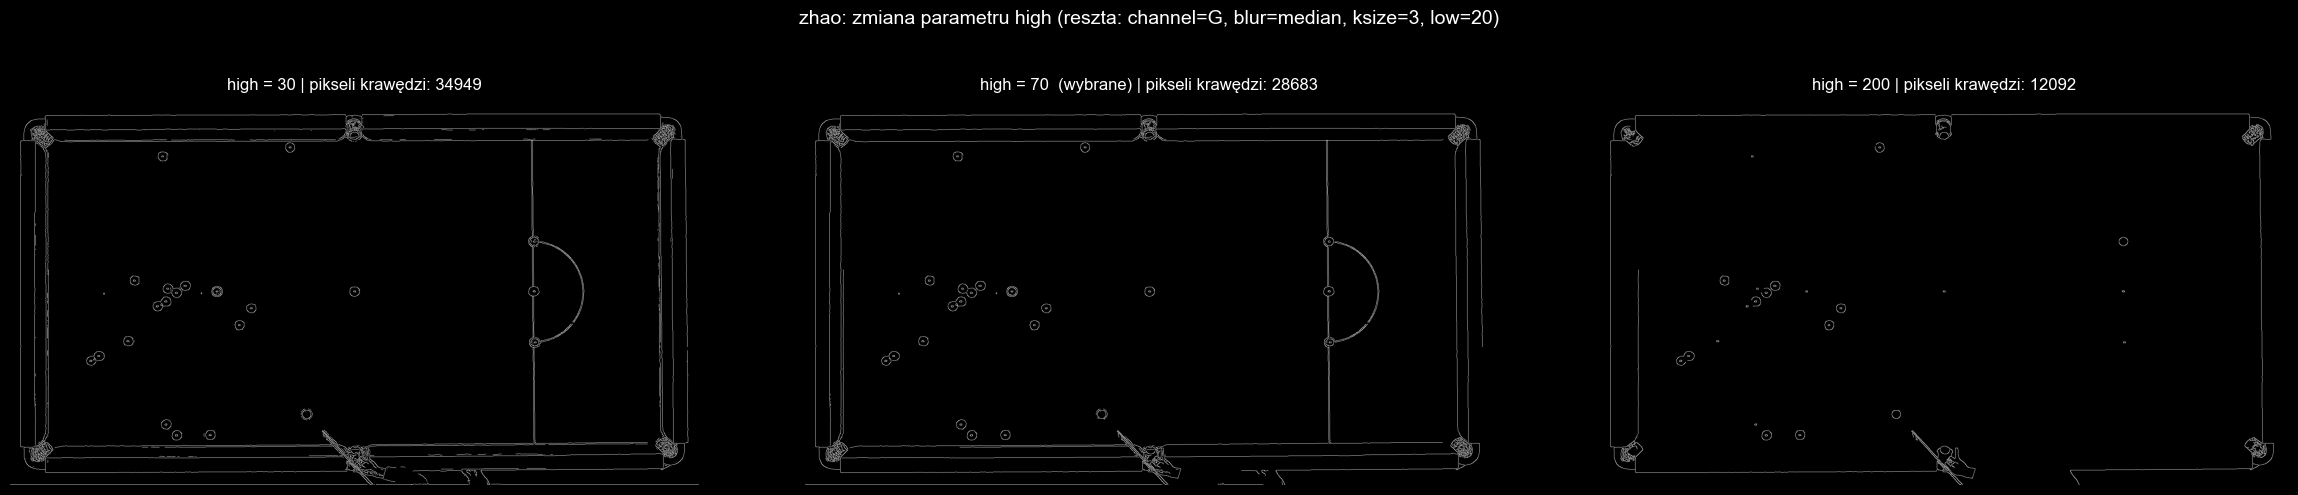

In [56]:
DEFAULT = dict(channel='G', blur='median', ksize=3, low=20, high=70)

def canny_edges(img, channel, blur, ksize, low, high):
    ch = get_channel(img, channel)
    if blur == 'median':
        ch = cv2.medianBlur(ch, ksize)
    elif blur == 'gauss':
        ch = cv2.GaussianBlur(ch, (ksize, ksize), 0)
    return cv2.Canny(ch, low, high)

def compare_param(name, param, values, defaults=DEFAULT):
    img = images[name]
    fig, ax = plt.subplots(1, len(values), figsize=(8 * len(values), 5))
    for a, v in zip(ax, values):
        p = {**defaults, param: v}
        e = canny_edges(img, **p)
        a.imshow(e, cmap='gray')
        mark = '  (wybrane)' if v == defaults[param] else ''
        a.set_title(f'{param} = {v}{mark} | pikseli krawędzi: {np.count_nonzero(e)}')
        a.axis('off')
    rest = ', '.join(f'{k}={v}' for k, v in defaults.items() if k != param)
    fig.suptitle(f'{name}: zmiana parametru {param} (reszta: {rest})', fontsize=14)
    plt.tight_layout(rect=(0, 0, 1, 0.90))
    plt.show()

cases = [
    ('channel', ['gray', 'G', 'R']),
    ('ksize',   [3, 9, 15]),
    ('low',     [0, 20, 60]),
    ('high',    [30, 70, 200]),
]
for param, values in cases:
    compare_param('zhao', param, values)

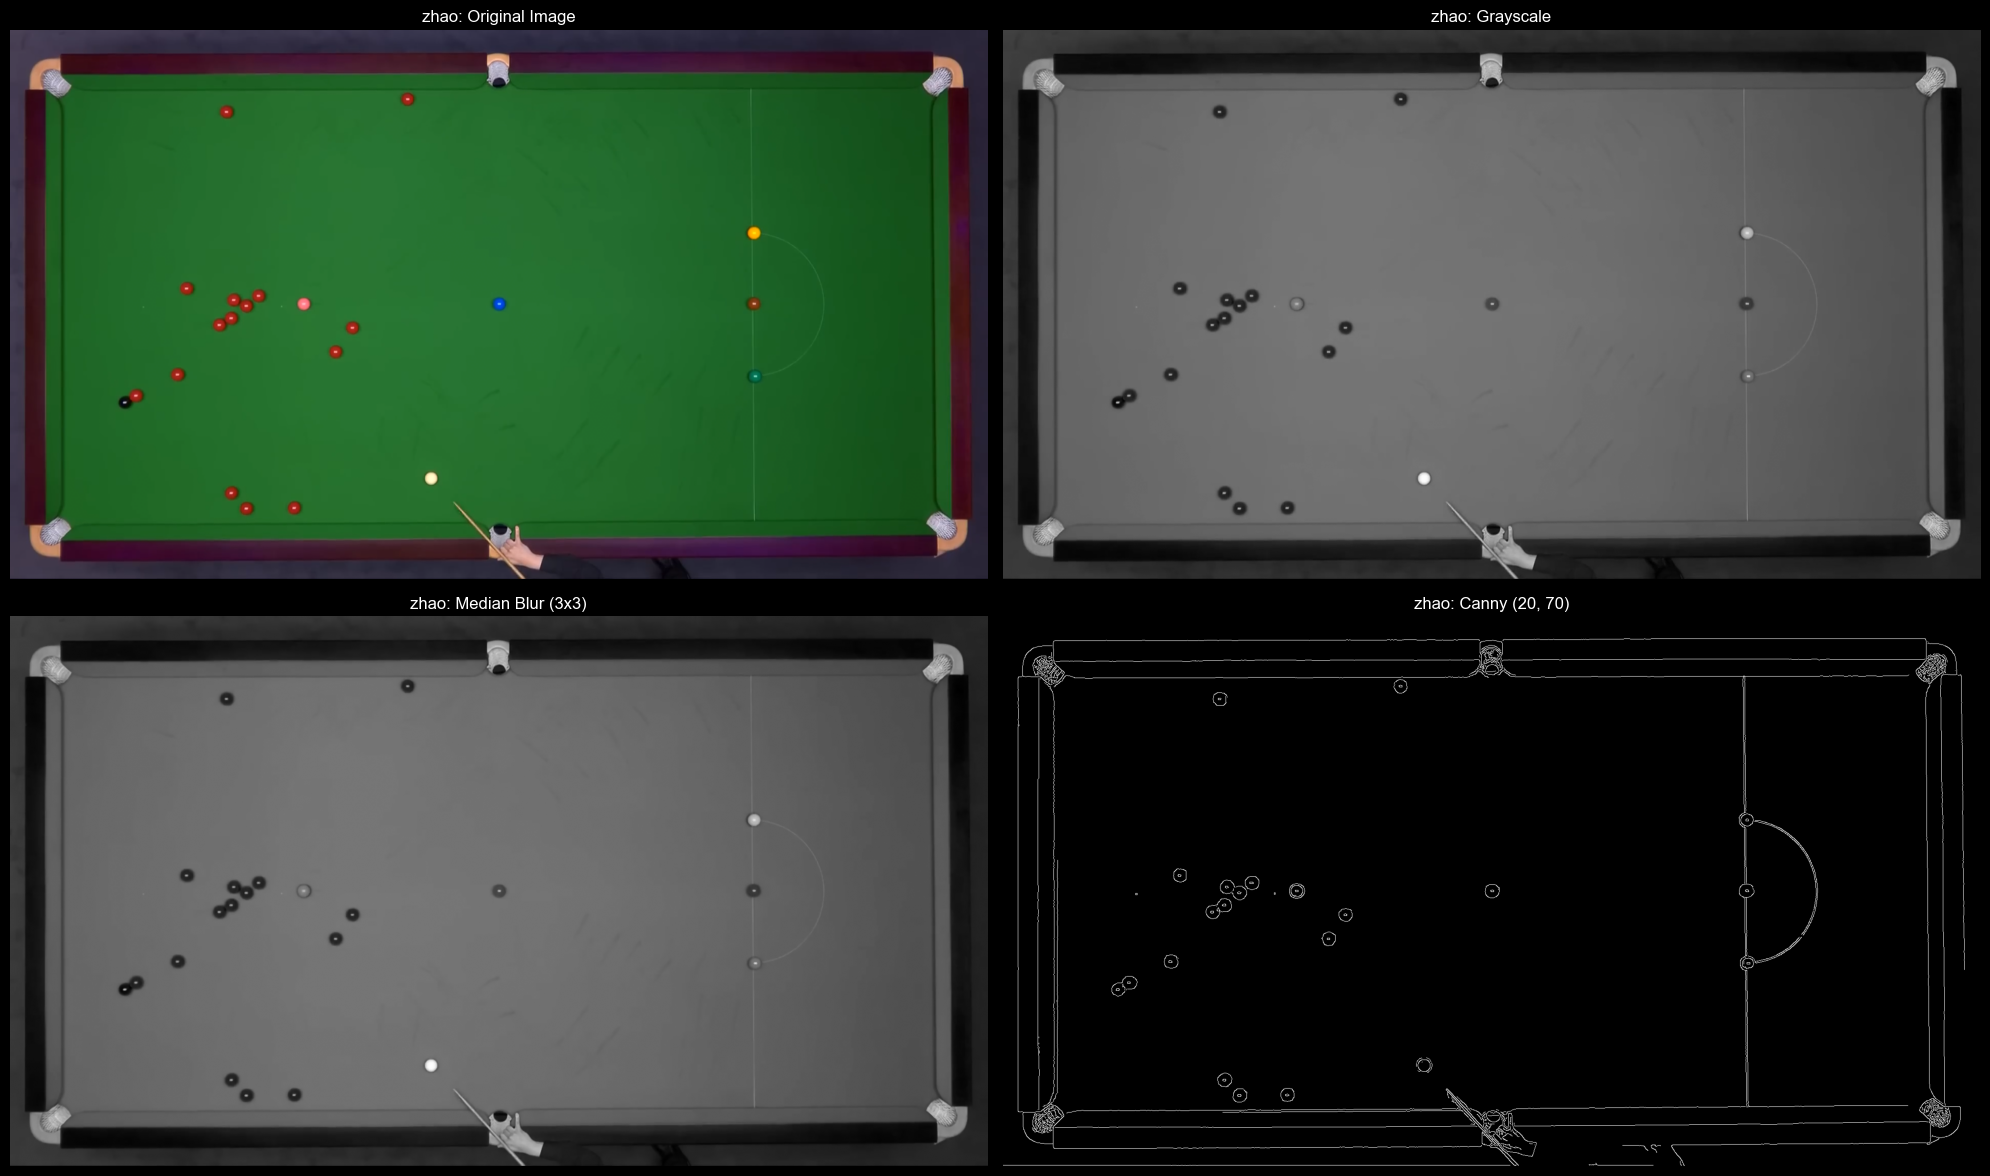

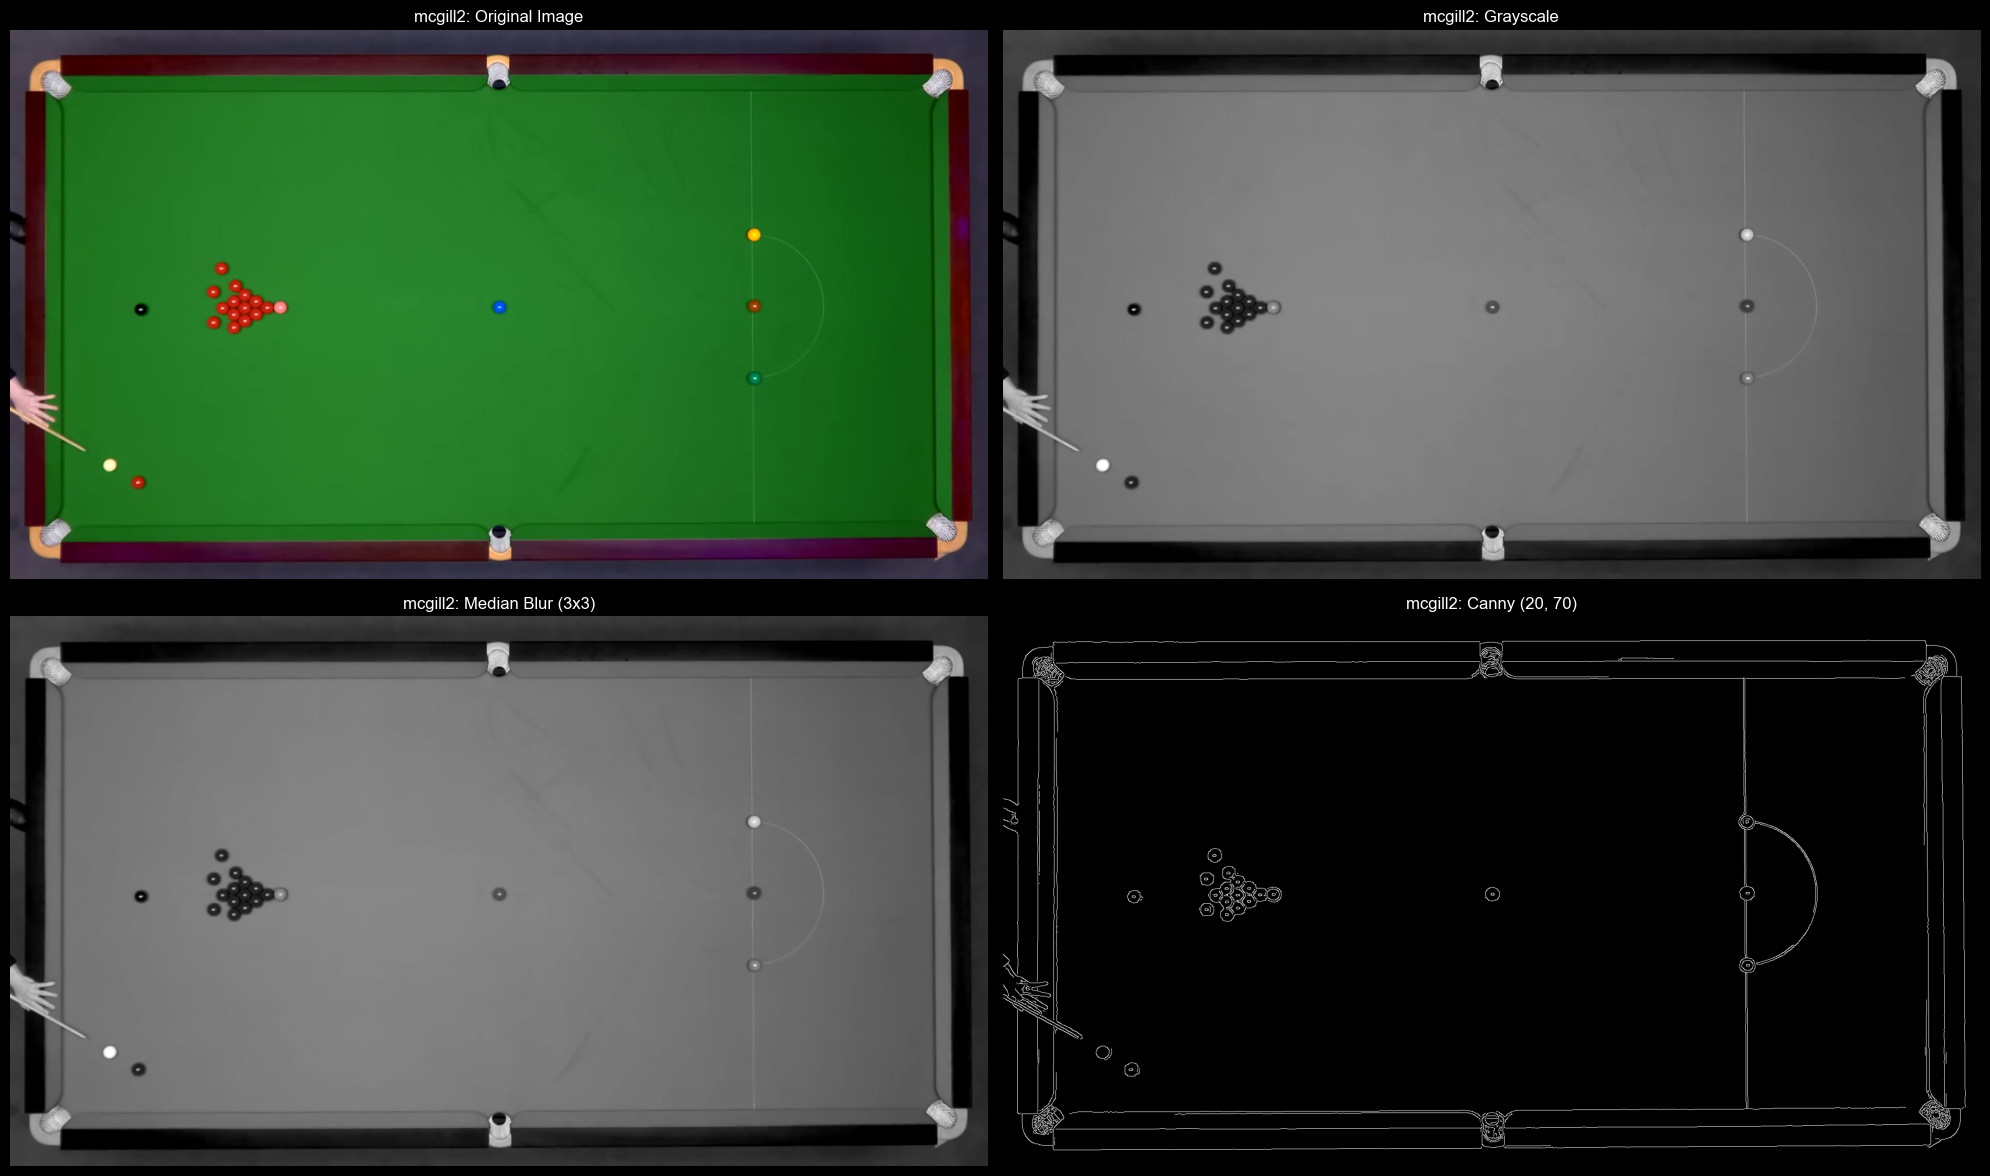

In [22]:
results = {}
for img, name in [(zhao, 'zhao'), (mcgill2, 'mcgill2')]:
    gray_image, blurredImage, edgeImage = preprocess(img)
    show_preprocessing(img, gray_image, blurredImage, edgeImage, name)
    results[name] = (img, edgeImage)

In [43]:
def directional_edges(edges, L):
    kh = cv2.getStructuringElement(cv2.MORPH_RECT, (L, 1))
    kv = cv2.getStructuringElement(cv2.MORPH_RECT, (1, L))
    eh = cv2.morphologyEx(cv2.morphologyEx(edges, cv2.MORPH_OPEN, kh), cv2.MORPH_CLOSE, kh)
    ev = cv2.morphologyEx(cv2.morphologyEx(edges, cv2.MORPH_OPEN, kv), cv2.MORPH_CLOSE, kv)
    return eh, ev

def select_bands(lines_h, lines_v, W, H, margin=0.18):
    """Z każdej strony stołu wybiera najbardziej wewnętrzną linię w pasie margin przy brzegu."""
    bands = []
    if lines_h is not None:
        r, t = lines_h[:, 0, 0], lines_h[:, 0, 1]
        y = (r - (W / 2) * np.cos(t)) / np.sin(t)          # y linii w środku szerokości obrazu
        top, bottom = y < margin * H, y > (1 - margin) * H
        if top.any():    bands.append(lines_h[top][np.argmax(y[top])])
        if bottom.any(): bands.append(lines_h[bottom][np.argmin(y[bottom])])
    if lines_v is not None:
        r, t = lines_v[:, 0, 0], lines_v[:, 0, 1]
        x = (r - (H / 2) * np.sin(t)) / np.cos(t)          # x linii w środku wysokości obrazu
        left, right = x < margin * W, x > (1 - margin) * W
        if left.any():  bands.append(lines_v[left][np.argmax(x[left])])
        if right.any(): bands.append(lines_v[right][np.argmin(x[right])])
    return np.array(bands) if bands else None

def interactive_hough_lines(name='zhao', L=25, frac=0.4, rho=1, theta_deg=1.0, margin=0.18):
    img = images[name]
    H, W = img.shape[:2]
    edges = cv2.Canny(cv2.medianBlur(get_channel(img, 'G'), 3), 20, 70)

    eh, ev = directional_edges(edges, L)
    lines_h = cv2.HoughLines(eh, rho, np.deg2rad(theta_deg), int(frac * W))
    lines_v = cv2.HoughLines(ev, rho, np.deg2rad(theta_deg), int(frac * H))
    found = [l for l in (lines_h, lines_v) if l is not None]
    all_lines = np.vstack(found) if found else None
    bands = select_bands(lines_h, lines_v, W, H, margin)

    fig, ax = plt.subplots(1, 3, figsize=(30, 7))
    ax[0].imshow(cv2.bitwise_or(eh, ev), cmap='gray')
    ax[0].set_title(f'{name}: krawędzie po otwarciu kierunkowym, L={L}')
    for a, lines, title in [(ax[1], all_lines, 'wszystkie linie'), (ax[2], bands, 'wybrane bandy')]:
        canvas = np.zeros_like(img)
        if lines is not None:
            drawhoughLinesOnImage(canvas, lines)
        n = 0 if lines is None else len(lines)
        a.imshow(blend_images(canvas, img)[..., ::-1])
        a.set_title(f'{title}: {n}')
    for a in ax: a.axis('off')
    plt.tight_layout()
    plt.show()
    return bands


In [44]:
interact(interactive_hough_lines,
         name=Dropdown(options=list(images), value='zhao'),
         L=IntSlider(min=0, max=60, step=1, value=3),
         frac=FloatSlider(min=0.1, max=1.0, step=0.01, value=0.40),
         rho=IntSlider(min=1, max=10, step=1, value=5),
         theta_deg=FloatSlider(min=0.25, max=5.0, step=0.05, value=3.10));

interactive(children=(Dropdown(description='name', options=('zhao', 'mcgill2'), value='zhao'), IntSlider(value…

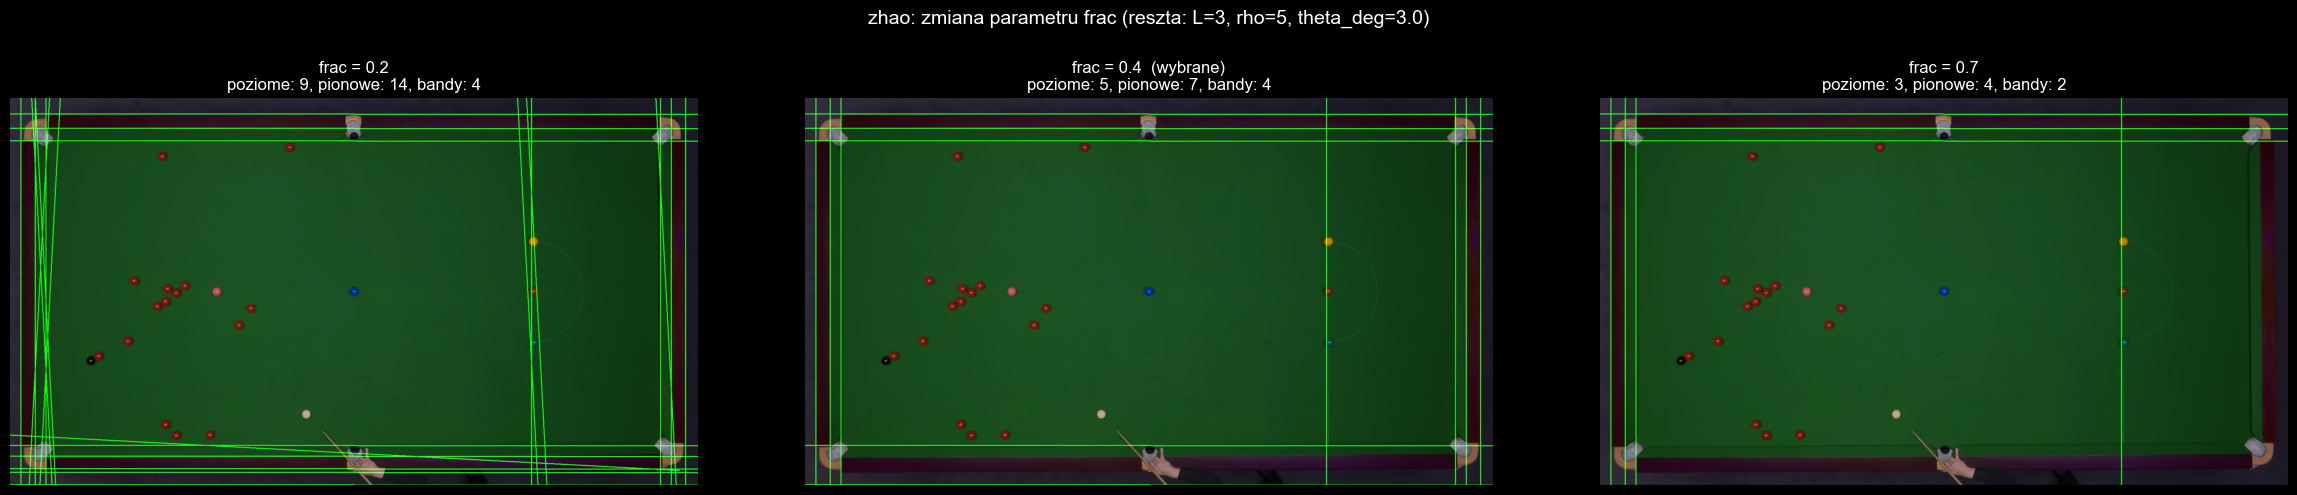

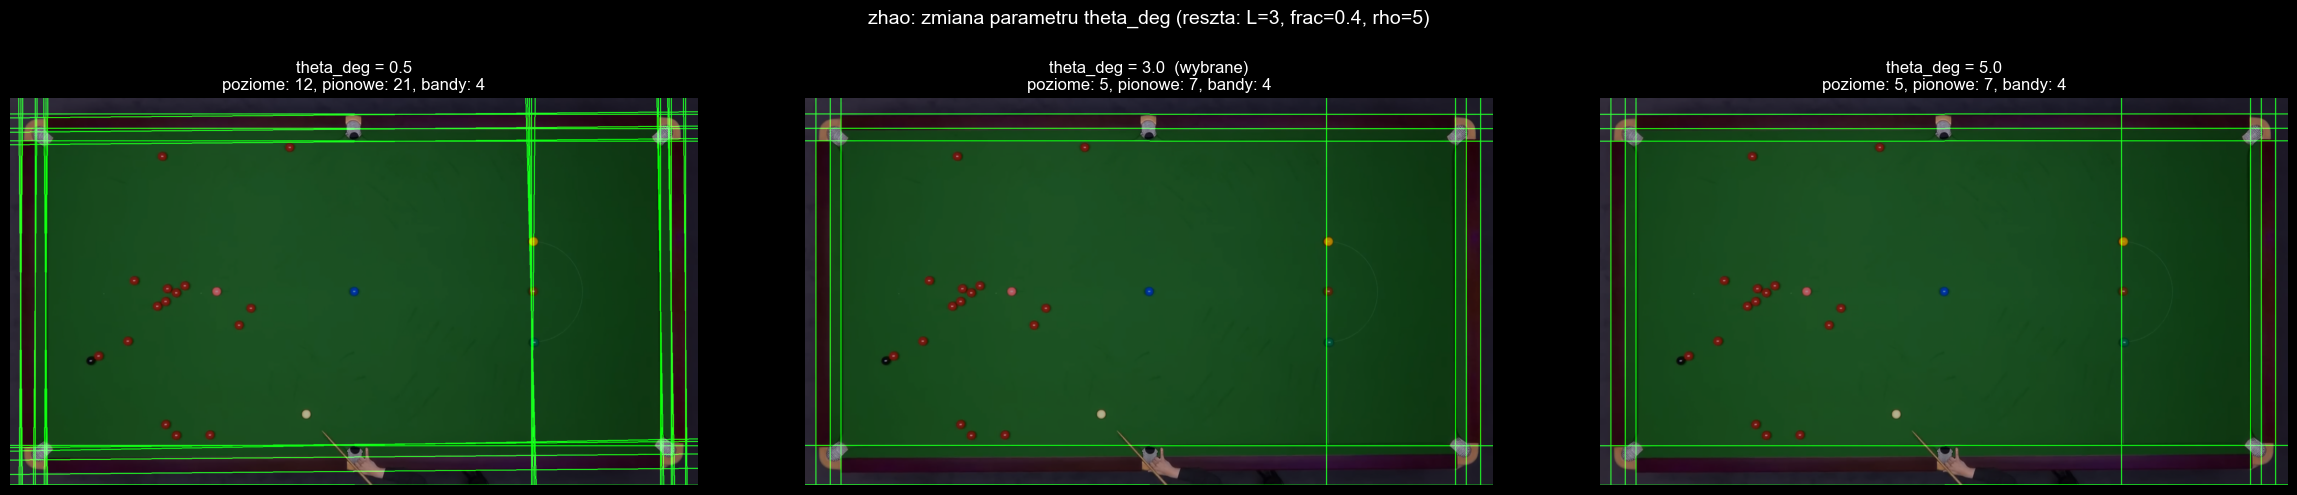

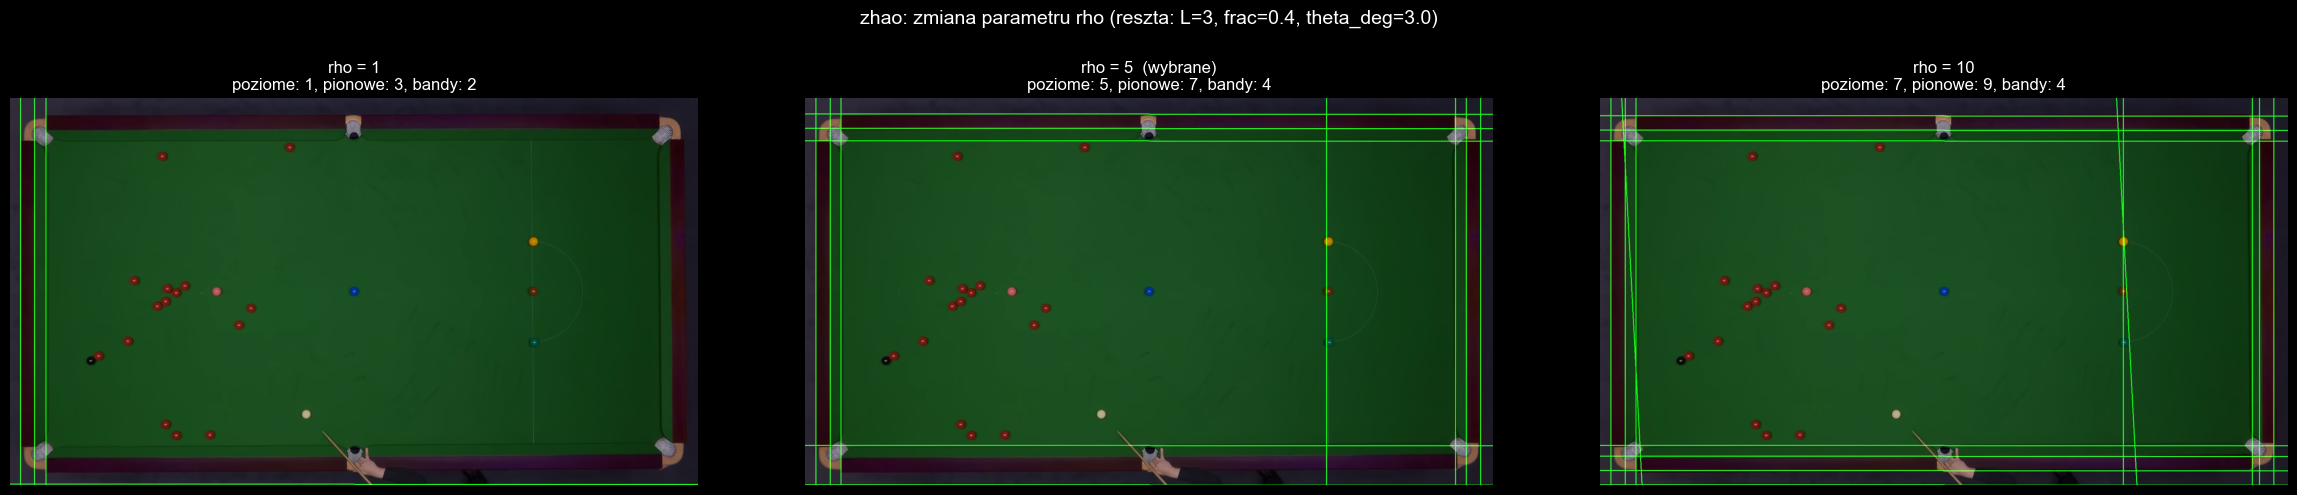

C:\Users\pauko\AppData\Local\Temp\ipykernel_31332\1829699953.py:13: RuntimeWarning: divide by zero encountered in divide
  y = (r - (W / 2) * np.cos(t)) / np.sin(t)          # y linii w środku szerokości obrazu


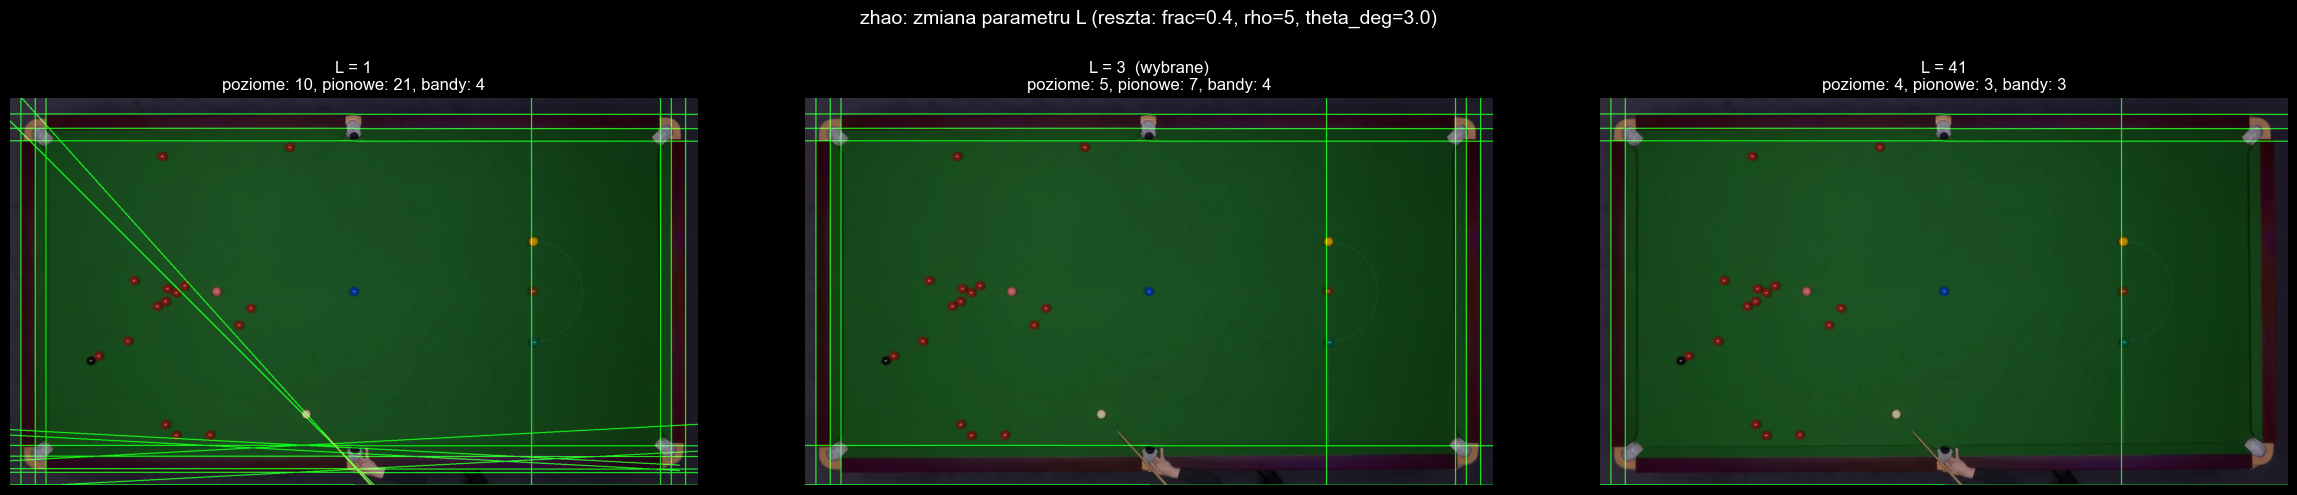

In [54]:
LINE_DEFAULT = dict(L=3, frac=0.40, rho=5, theta_deg=3.0)

def hough_lines(img, L, frac, rho, theta_deg):
    H, W = img.shape[:2]
    edges = cv2.Canny(cv2.medianBlur(get_channel(img, 'G'), 3), 20, 70)
    eh, ev = directional_edges(edges, L)
    lines_h = cv2.HoughLines(eh, rho, np.deg2rad(theta_deg), int(frac * W))
    lines_v = cv2.HoughLines(ev, rho, np.deg2rad(theta_deg), int(frac * H))
    return lines_h, lines_v

def compare_line_param(name, param, values, defaults=LINE_DEFAULT):
    img = images[name]
    H, W = img.shape[:2]
    fig, ax = plt.subplots(1, len(values), figsize=(8 * len(values), 5))
    for a, v in zip(ax, values):
        p = {**defaults, param: v}
        lines_h, lines_v = hough_lines(img, **p)
        found = [l for l in (lines_h, lines_v) if l is not None]
        all_lines = np.vstack(found) if found else None
        bands = select_bands(lines_h, lines_v, W, H)

        canvas = np.zeros_like(img)
        if all_lines is not None:
            drawhoughLinesOnImage(canvas, all_lines)
        a.imshow(blend_images(canvas, img)[..., ::-1])

        nh = 0 if lines_h is None else len(lines_h)
        nv = 0 if lines_v is None else len(lines_v)
        nb = 0 if bands is None else len(bands)
        mark = '  (wybrane)' if v == defaults[param] else ''
        a.set_title(f'{param} = {v}{mark}\npoziome: {nh}, pionowe: {nv}, bandy: {nb}')
        a.axis('off')
    rest = ', '.join(f'{k}={v}' for k, v in defaults.items() if k != param)
    fig.suptitle(f'{name}: zmiana parametru {param} (reszta: {rest})', fontsize=14)
    plt.tight_layout(rect=(0, 0, 1, 0.90))
    plt.show()

line_cases = [
    ('frac',      [0.20, 0.40, 0.70]),
    ('theta_deg', [0.5, 3.0, 5.0]),
    ('rho',       [1, 5, 10]),
    ('L',         [1, 3, 41]),
]
for param, values in line_cases:
    compare_line_param('zhao', param, values)

In [46]:
# parametry band ustalone w poprzednim kroku
LINE_PARAMS = dict(L=3, frac=0.40, rho=5, theta_deg=3.0, margin=0.18)

def detect_bands(img, L, frac, rho, theta_deg, margin):
    H, W = img.shape[:2]
    edges = cv2.Canny(cv2.medianBlur(get_channel(img, 'G'), 3), 20, 70)
    eh, ev = directional_edges(edges, L)
    lines_h = cv2.HoughLines(eh, rho, np.deg2rad(theta_deg), int(frac * W))
    lines_v = cv2.HoughLines(ev, rho, np.deg2rad(theta_deg), int(frac * H))
    return select_bands(lines_h, lines_v, W, H, margin)

def bands_box(bands, W, H):
    """Prostokąt (left, top, right, bottom) wyznaczony przez 4 bandy."""
    if bands is None or len(bands) < 4:
        return None
    xs, ys = [], []
    for (r, t), in bands:
        if abs(np.sin(t)) > abs(np.cos(t)):                 # linia pozioma
            ys.append((r - (W / 2) * np.cos(t)) / np.sin(t))
        else:                                               # linia pionowa
            xs.append((r - (H / 2) * np.sin(t)) / np.cos(t))
    if len(xs) < 2 or len(ys) < 2:
        return None
    return min(xs), min(ys), max(xs), max(ys)

def interactive_hough_circles(name='zhao', dp=1.0, minDist=15, param1=70, param2=18,
                              minRadius=8, maxRadius=16, inside=True):
    img = images[name]
    H, W = img.shape[:2]
    blurred = cv2.medianBlur(get_channel(img, 'G'), 3)

    circles = cv2.HoughCircles(blurred, cv2.HOUGH_GRADIENT, dp=dp, minDist=minDist,
                               param1=param1, param2=param2,
                               minRadius=minRadius, maxRadius=maxRadius)
    n_all = 0 if circles is None else circles.shape[1]

    if inside and circles is not None:
        box = bands_box(detect_bands(img, **LINE_PARAMS), W, H)
        if box is not None:
            l, t, r, b = box
            x, y = circles[0, :, 0], circles[0, :, 1]
            keep = (x > l) & (x < r) & (y > t) & (y < b)
            circles = circles[:, keep]
    n = 0 if circles is None else circles.shape[1]

    out = img.copy()
    if circles is not None:
        for x, y, r in np.round(circles[0]).astype(int):
            cv2.circle(out, (x, y), r, (0, 255, 0), 2)
            cv2.circle(out, (x, y), 2, (0, 0, 255), 3)

    fig, ax = plt.subplots(1, 2, figsize=(22, 7))
    ax[0].imshow(cv2.Canny(blurred, param1 // 2, param1), cmap='gray')
    ax[0].set_title(f'{name}: Canny wewnątrz HoughCircles ({param1 // 2}, {param1})')
    ax[1].imshow(out[..., ::-1])
    ax[1].set_title(f'dp={dp}, minDist={minDist}, p1={param1}, p2={param2}, '
                    f'r=[{minRadius}, {maxRadius}] | okręgów: {n}'
                    + (f' (przed filtrem: {n_all})' if inside else ''))
    for a in ax: a.axis('off')
    plt.tight_layout()
    plt.show()
    return circles

In [48]:
interact(interactive_hough_circles,
         name=Dropdown(options=list(images), value='zhao'),
         dp=FloatSlider(min=1.0, max=3.0, step=0.1, value=1.0),
         minDist=IntSlider(min=1, max=100, step=1, value=24),
         param1=IntSlider(min=10, max=200, step=5, value=50),
         param2=IntSlider(min=5, max=100, step=1, value=12),
         minRadius=IntSlider(min=0, max=40, step=1, value=8),
         maxRadius=IntSlider(min=0, max=60, step=1, value=14),
         inside=Checkbox(value=True));

interactive(children=(Dropdown(description='name', options=('zhao', 'mcgill2'), value='zhao'), FloatSlider(val…

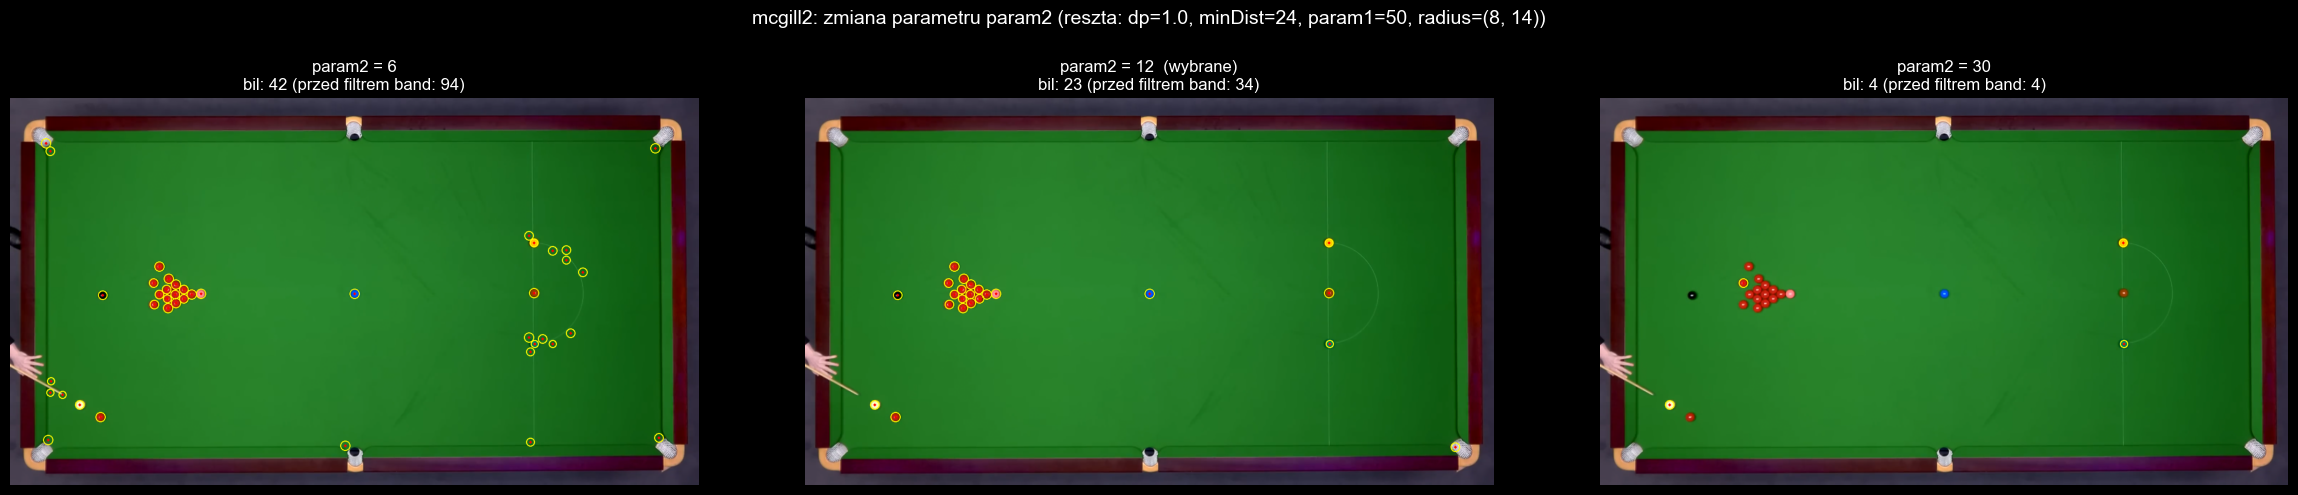

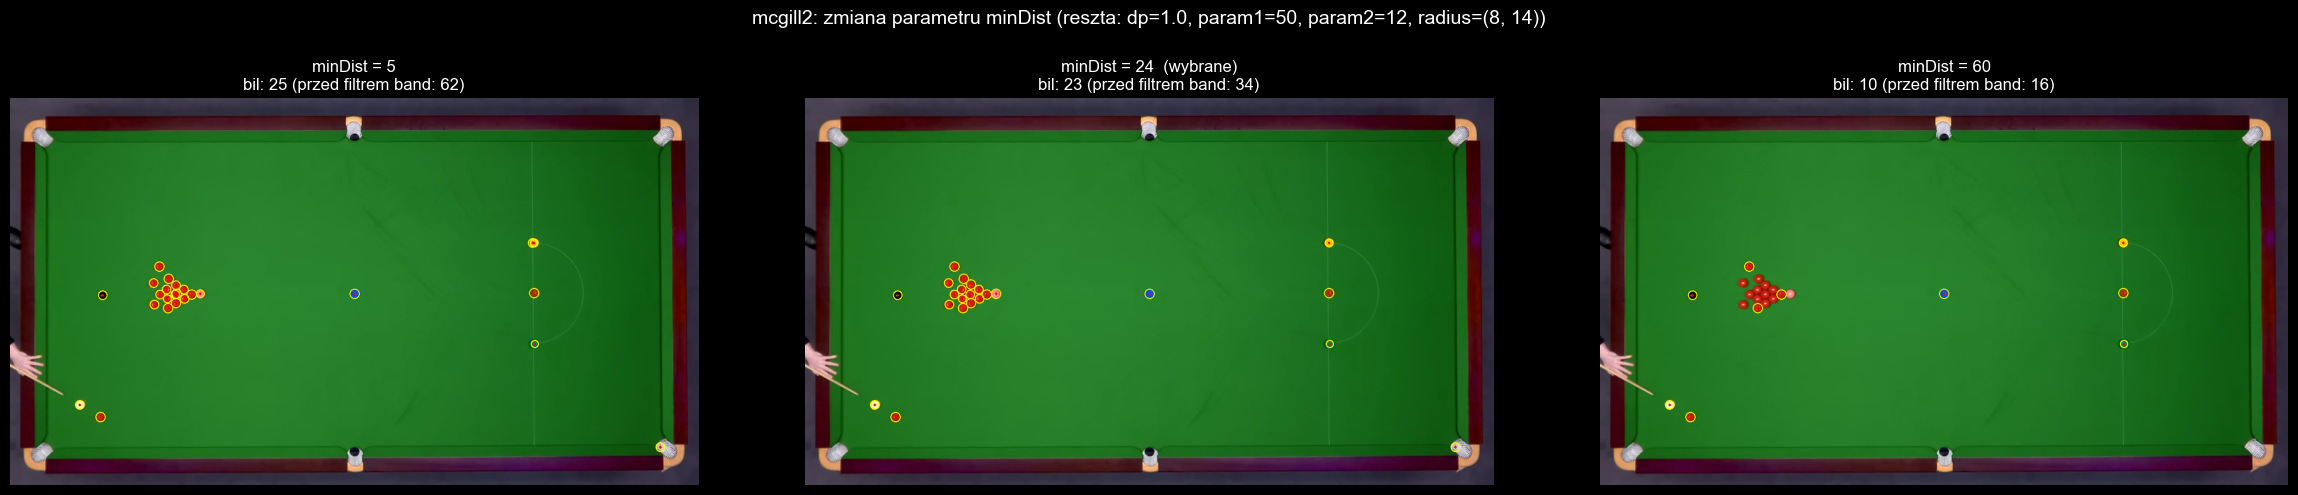

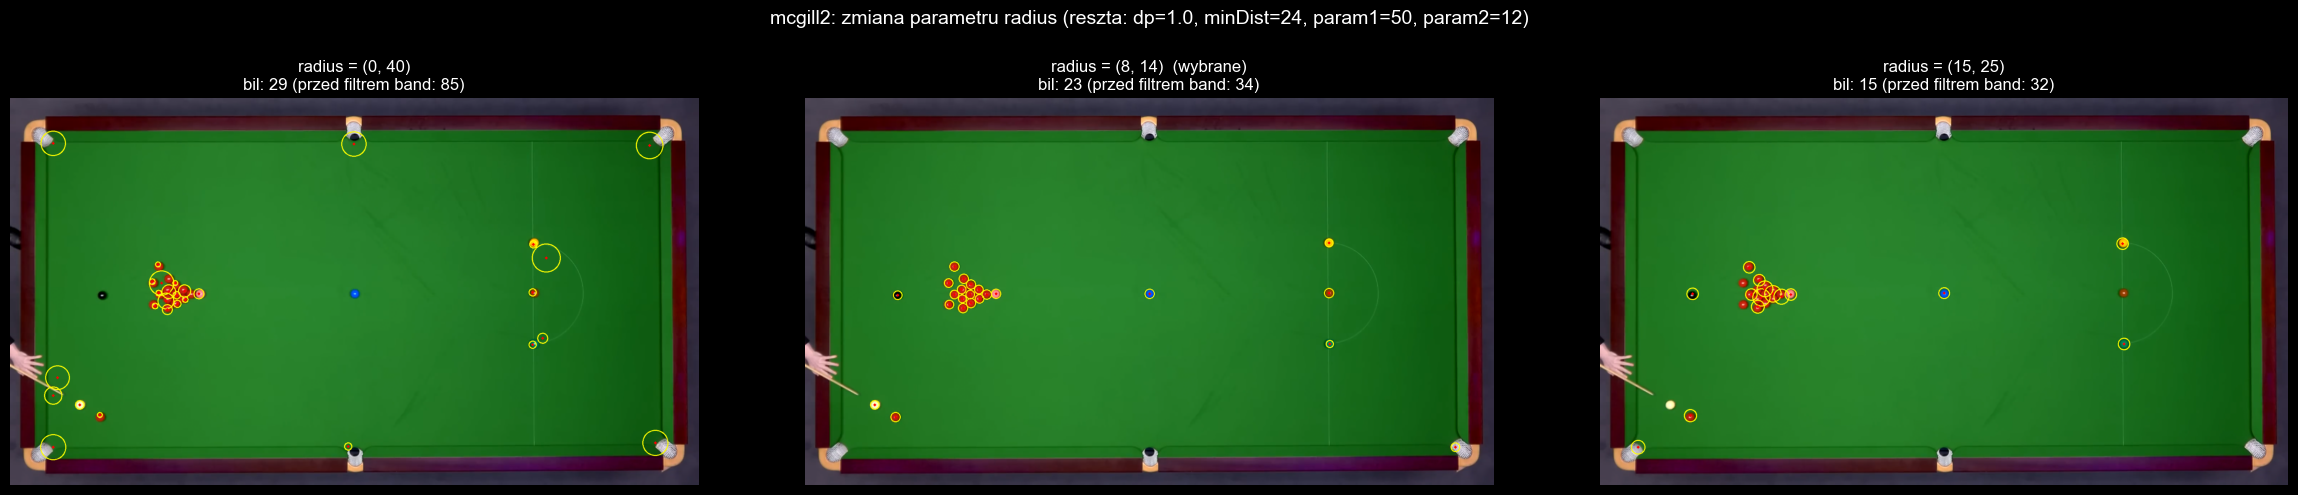

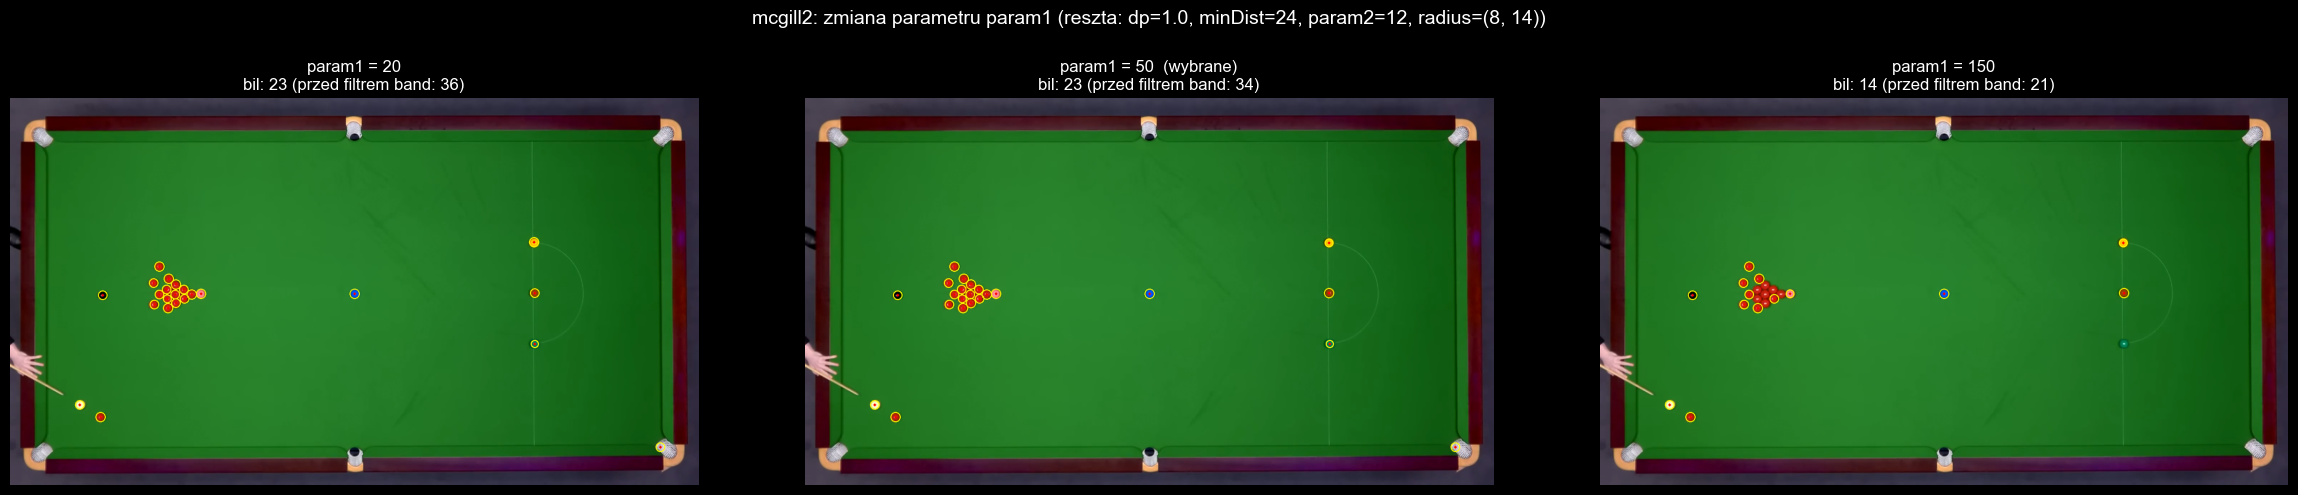

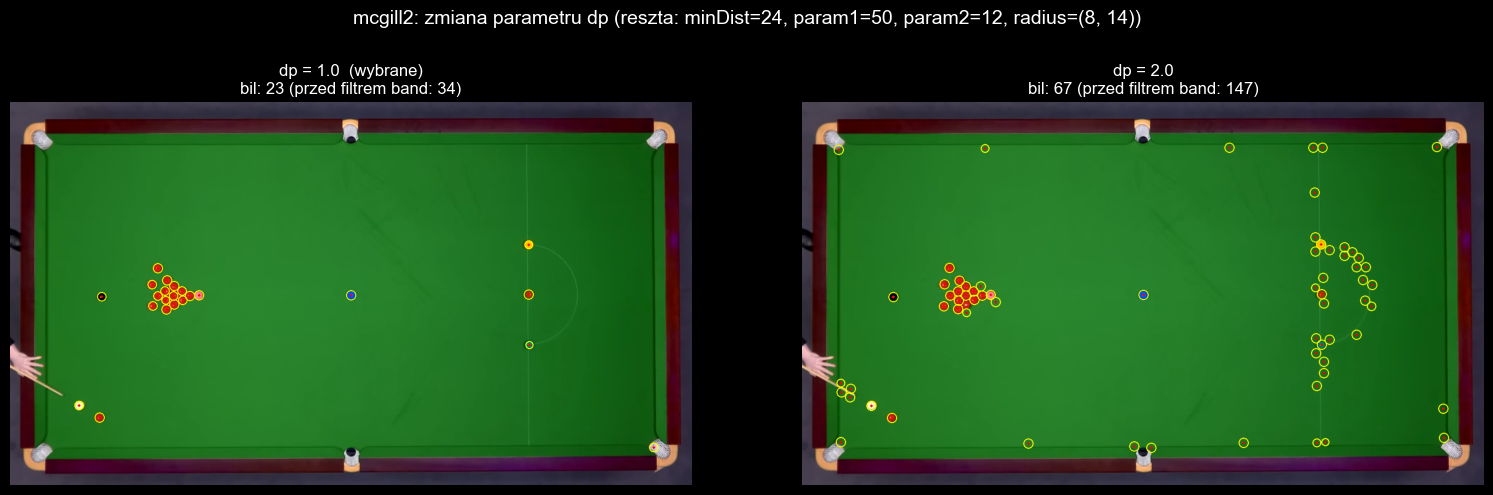

In [55]:
CIRCLE_DEFAULT = dict(dp=1.0, minDist=24, param1=50, param2=12, radius=(8, 14))

def hough_circles(img, dp, minDist, param1, param2, radius, box=None):
    blurred = cv2.medianBlur(get_channel(img, 'G'), 3)
    c = cv2.HoughCircles(blurred, cv2.HOUGH_GRADIENT, dp=dp, minDist=minDist,
                         param1=param1, param2=param2,
                         minRadius=radius[0], maxRadius=radius[1])
    c = np.empty((0, 3)) if c is None else c[0]
    n_all = len(c)
    if box is not None and len(c):
        l, t, r, b = box
        c = c[(c[:, 0] > l) & (c[:, 0] < r) & (c[:, 1] > t) & (c[:, 1] < b)]
    return c, n_all

def compare_circle_param(name, param, values, defaults=CIRCLE_DEFAULT, roi=None):
    img = images[name]
    H, W = img.shape[:2]
    box = bands_box(detect_bands(img, **LINE_PARAMS), W, H)   # bandy liczone raz
    fig, ax = plt.subplots(1, len(values), figsize=(8 * len(values), 5))
    for a, v in zip(ax, values):
        p = {**defaults, param: v}
        circles, n_all = hough_circles(img, **p, box=box)

        out = img.copy()
        for x, y, r in np.round(circles).astype(int):
            cv2.circle(out, (x, y), r, (0, 255, 255), 2)
            cv2.circle(out, (x, y), 2, (0, 0, 255), 3)
        if roi is not None:                       # (y0, y1, x0, x1) - zbliżenie
            y0, y1, x0, x1 = roi
            out = out[y0:y1, x0:x1]
        a.imshow(out[..., ::-1])

        mark = '  (wybrane)' if v == defaults[param] else ''
        a.set_title(f'{param} = {v}{mark}\nbil: {len(circles)} (przed filtrem band: {n_all})')
        a.axis('off')
    rest = ', '.join(f'{k}={v}' for k, v in defaults.items() if k != param)
    fig.suptitle(f'{name}: zmiana parametru {param} (reszta: {rest})', fontsize=14)
    plt.tight_layout(rect=(0, 0, 1, 0.90))
    plt.show()

circle_cases = [
    ('param2',  [6, 12, 30]),
    ('minDist', [5, 24, 60]),
    ('radius',  [(0, 40), (8, 14), (15, 25)]),
    ('param1',  [20, 50, 150]),
    ('dp',      [1.0, 2.0]),
]
for param, values in circle_cases:
    compare_circle_param('mcgill2', param, values)

In [49]:
# --- parametry ustalone w eksperymentach ---
PRE    = dict(channel='G', median_k=3, canny_low=20, canny_high=70)
LINES  = dict(L=3, frac=0.40, rho=5, theta_deg=3.0, margin=0.18)
CIRCLE = dict(dp=1.0, minDist=24, param1=50, param2=12, minRadius=8, maxRadius=14)

def preprocess_table(img):
    ch = get_channel(img, PRE['channel'])
    blurred = cv2.medianBlur(ch, PRE['median_k'])
    edges = cv2.Canny(blurred, PRE['canny_low'], PRE['canny_high'])
    return blurred, edges

def detect_table(img):
    """Zwraca (bands, circles): bands - tablica (k,1,2) z (rho, theta),
    circles - tablica (n,3) z (x, y, r) bil leżących wewnątrz band."""
    H, W = img.shape[:2]
    blurred, edges = preprocess_table(img)

    # bandy: morfologia kierunkowa + HoughLines osobno dla poziomych i pionowych
    eh, ev = directional_edges(edges, LINES['L'])
    theta = np.deg2rad(LINES['theta_deg'])
    lines_h = cv2.HoughLines(eh, LINES['rho'], theta, int(LINES['frac'] * W))
    lines_v = cv2.HoughLines(ev, LINES['rho'], theta, int(LINES['frac'] * H))
    bands = select_bands(lines_h, lines_v, W, H, LINES['margin'])

    # bile: HoughCircles na rozmytym kanale (Canny liczony wewnątrz)
    circles = cv2.HoughCircles(blurred, cv2.HOUGH_GRADIENT, **CIRCLE)
    circles = np.empty((0, 3)) if circles is None else circles[0]

    # post-processing: tylko okręgi wewnątrz prostokąta band
    box = bands_box(bands, W, H)
    if box is not None and len(circles):
        l, t, r, b = box
        x, y = circles[:, 0], circles[:, 1]
        circles = circles[(x > l) & (x < r) & (y > t) & (y < b)]

    return bands, circles

def draw_results(img, bands, circles):
    out = img.copy()
    if bands is not None:
        drawhoughLinesOnImage(out, bands)
    for x, y, r in np.round(circles).astype(int):
        cv2.circle(out, (x, y), r, (0, 255, 255), 2)
        cv2.circle(out, (x, y), 2, (0, 0, 255), 3)
    return out

def show_pipeline(img, name):
    blurred, edges = preprocess_table(img)
    bands, circles = detect_table(img)
    result = draw_results(img, bands, circles)
    nb = 0 if bands is None else len(bands)

    fig, ax = plt.subplots(2, 2, figsize=(20, 12))
    ax[0, 0].imshow(img[..., ::-1])
    ax[0, 0].set_title(f'{name}: obraz wejściowy')
    ax[0, 1].imshow(edges, cmap='gray')
    ax[0, 1].set_title(f'Krawędzie dla band: Canny({PRE["canny_low"]}, {PRE["canny_high"]})')
    ax[1, 0].imshow(cv2.Canny(blurred, CIRCLE['param1'] // 2, CIRCLE['param1']), cmap='gray')
    ax[1, 0].set_title(f'Krawędzie wewnątrz HoughCircles: Canny({CIRCLE["param1"] // 2}, {CIRCLE["param1"]})')
    ax[1, 1].imshow(result[..., ::-1])
    ax[1, 1].set_title(f'Wynik: band {nb}, bil {len(circles)}')
    for a in ax.ravel(): a.axis('off')
    plt.tight_layout()
    plt.show()
    return bands, circles

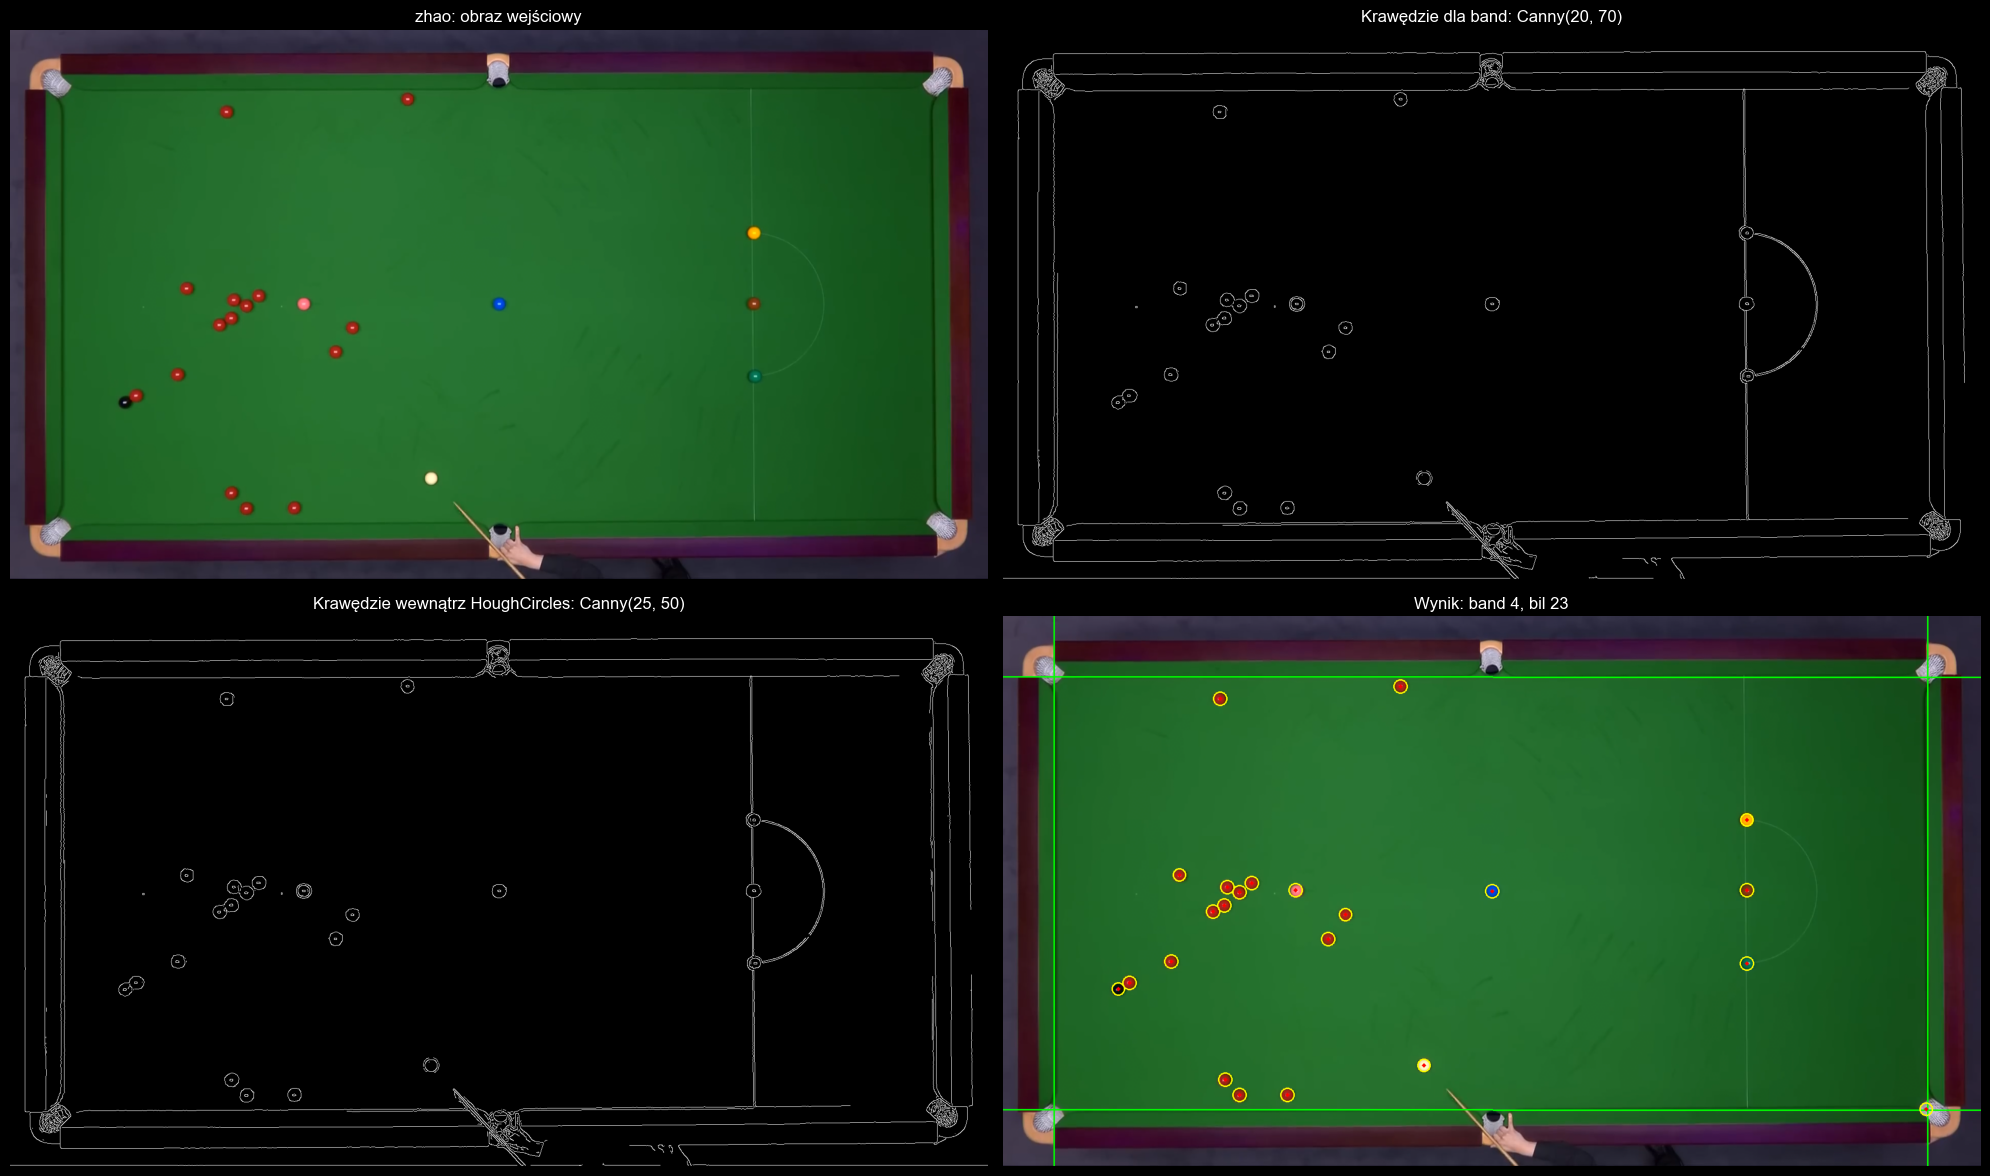

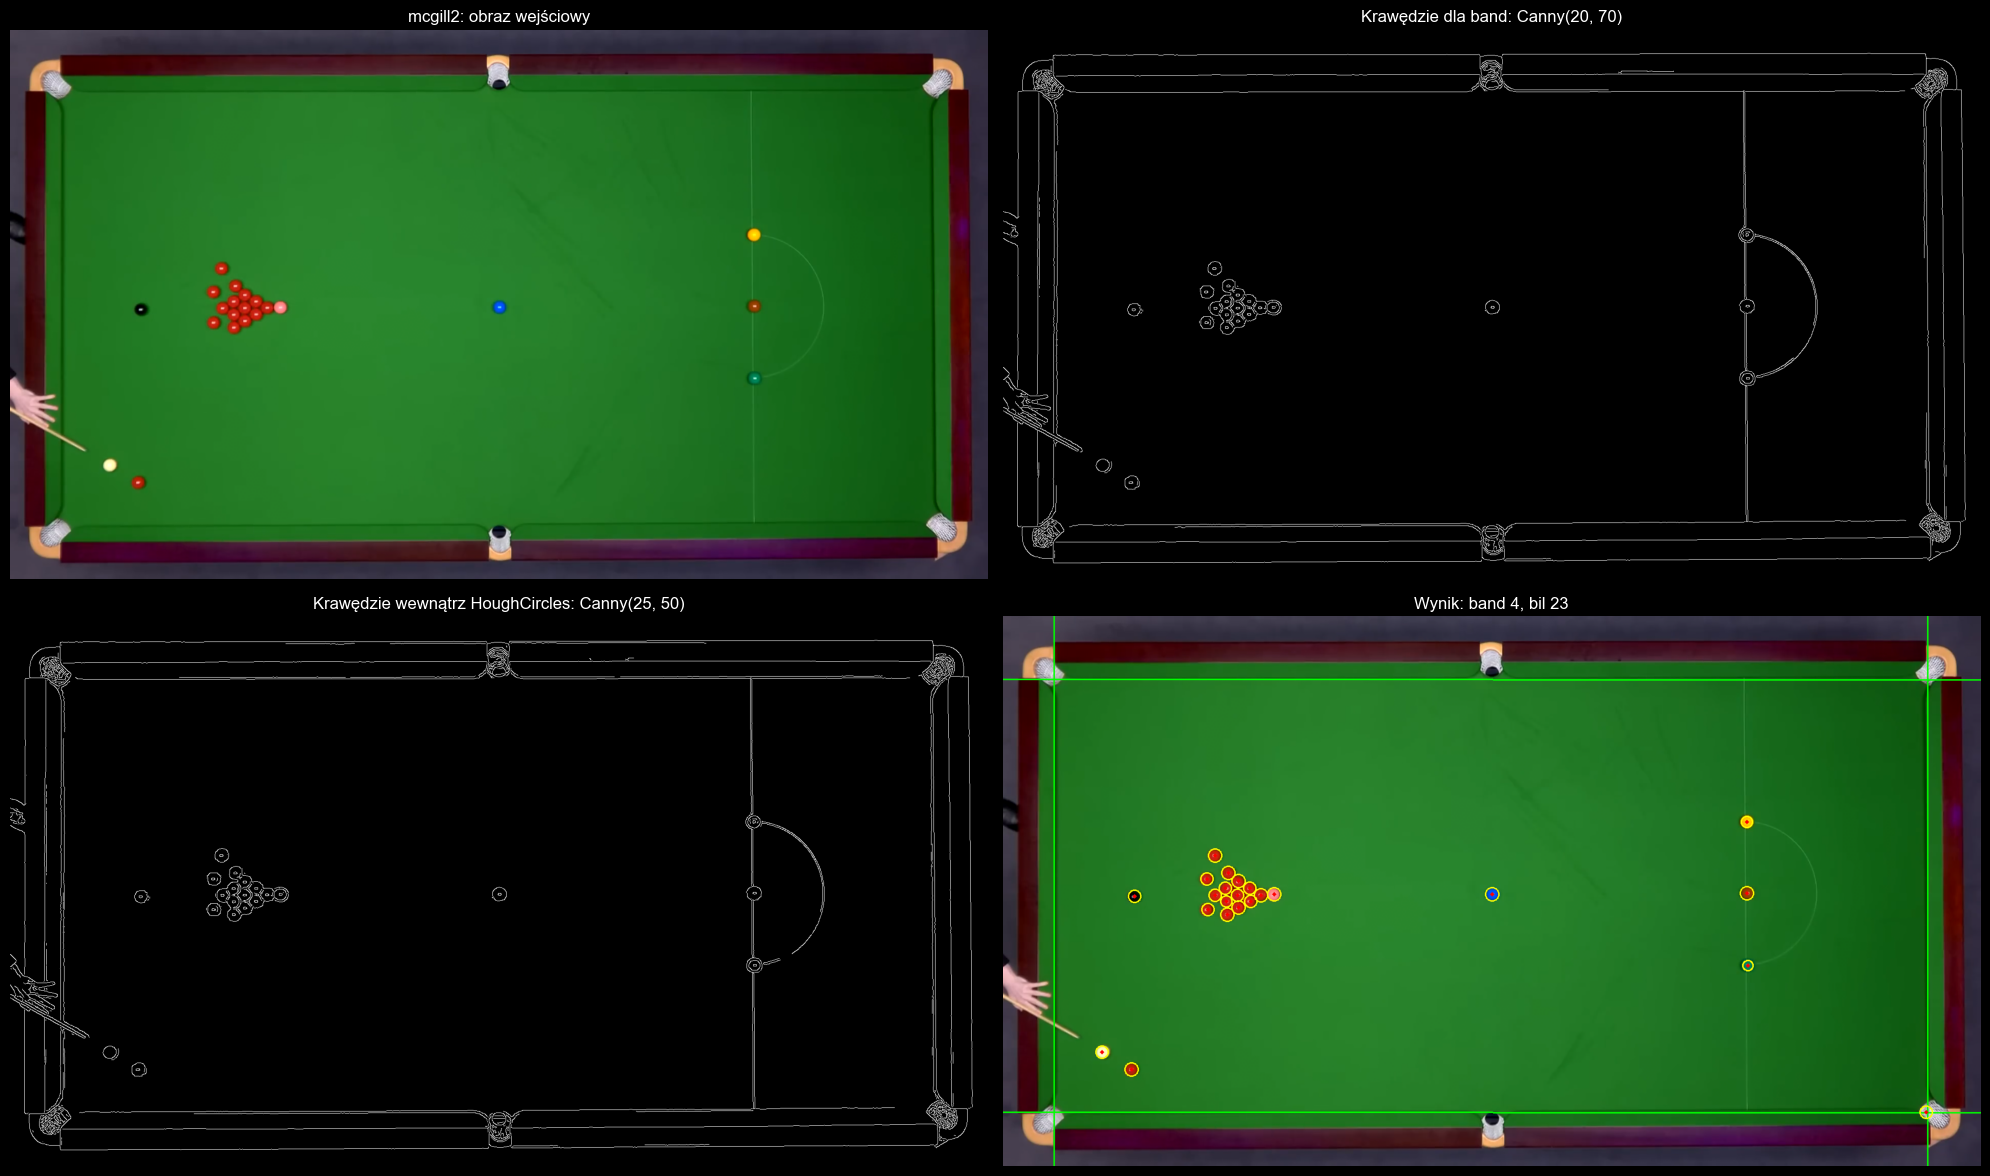

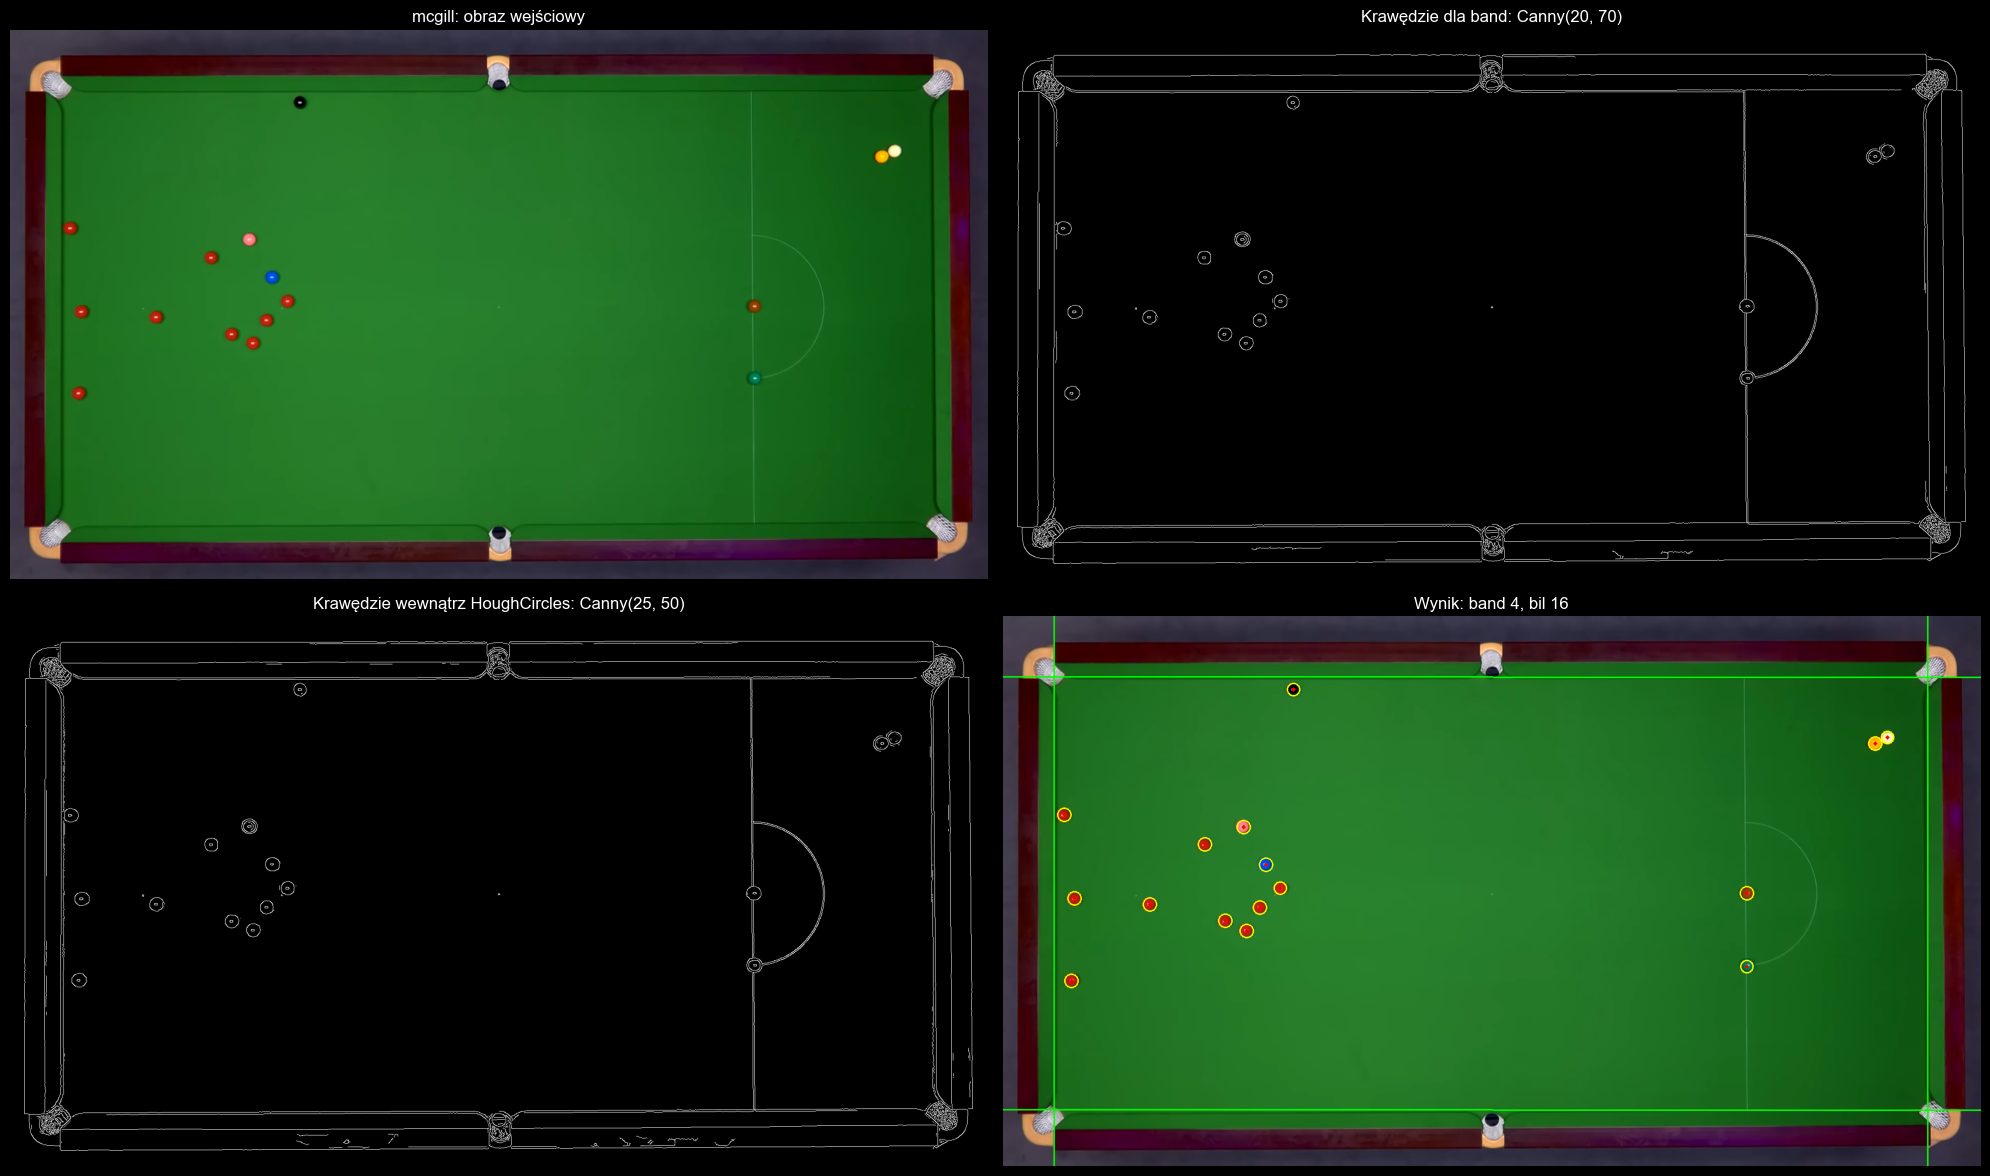

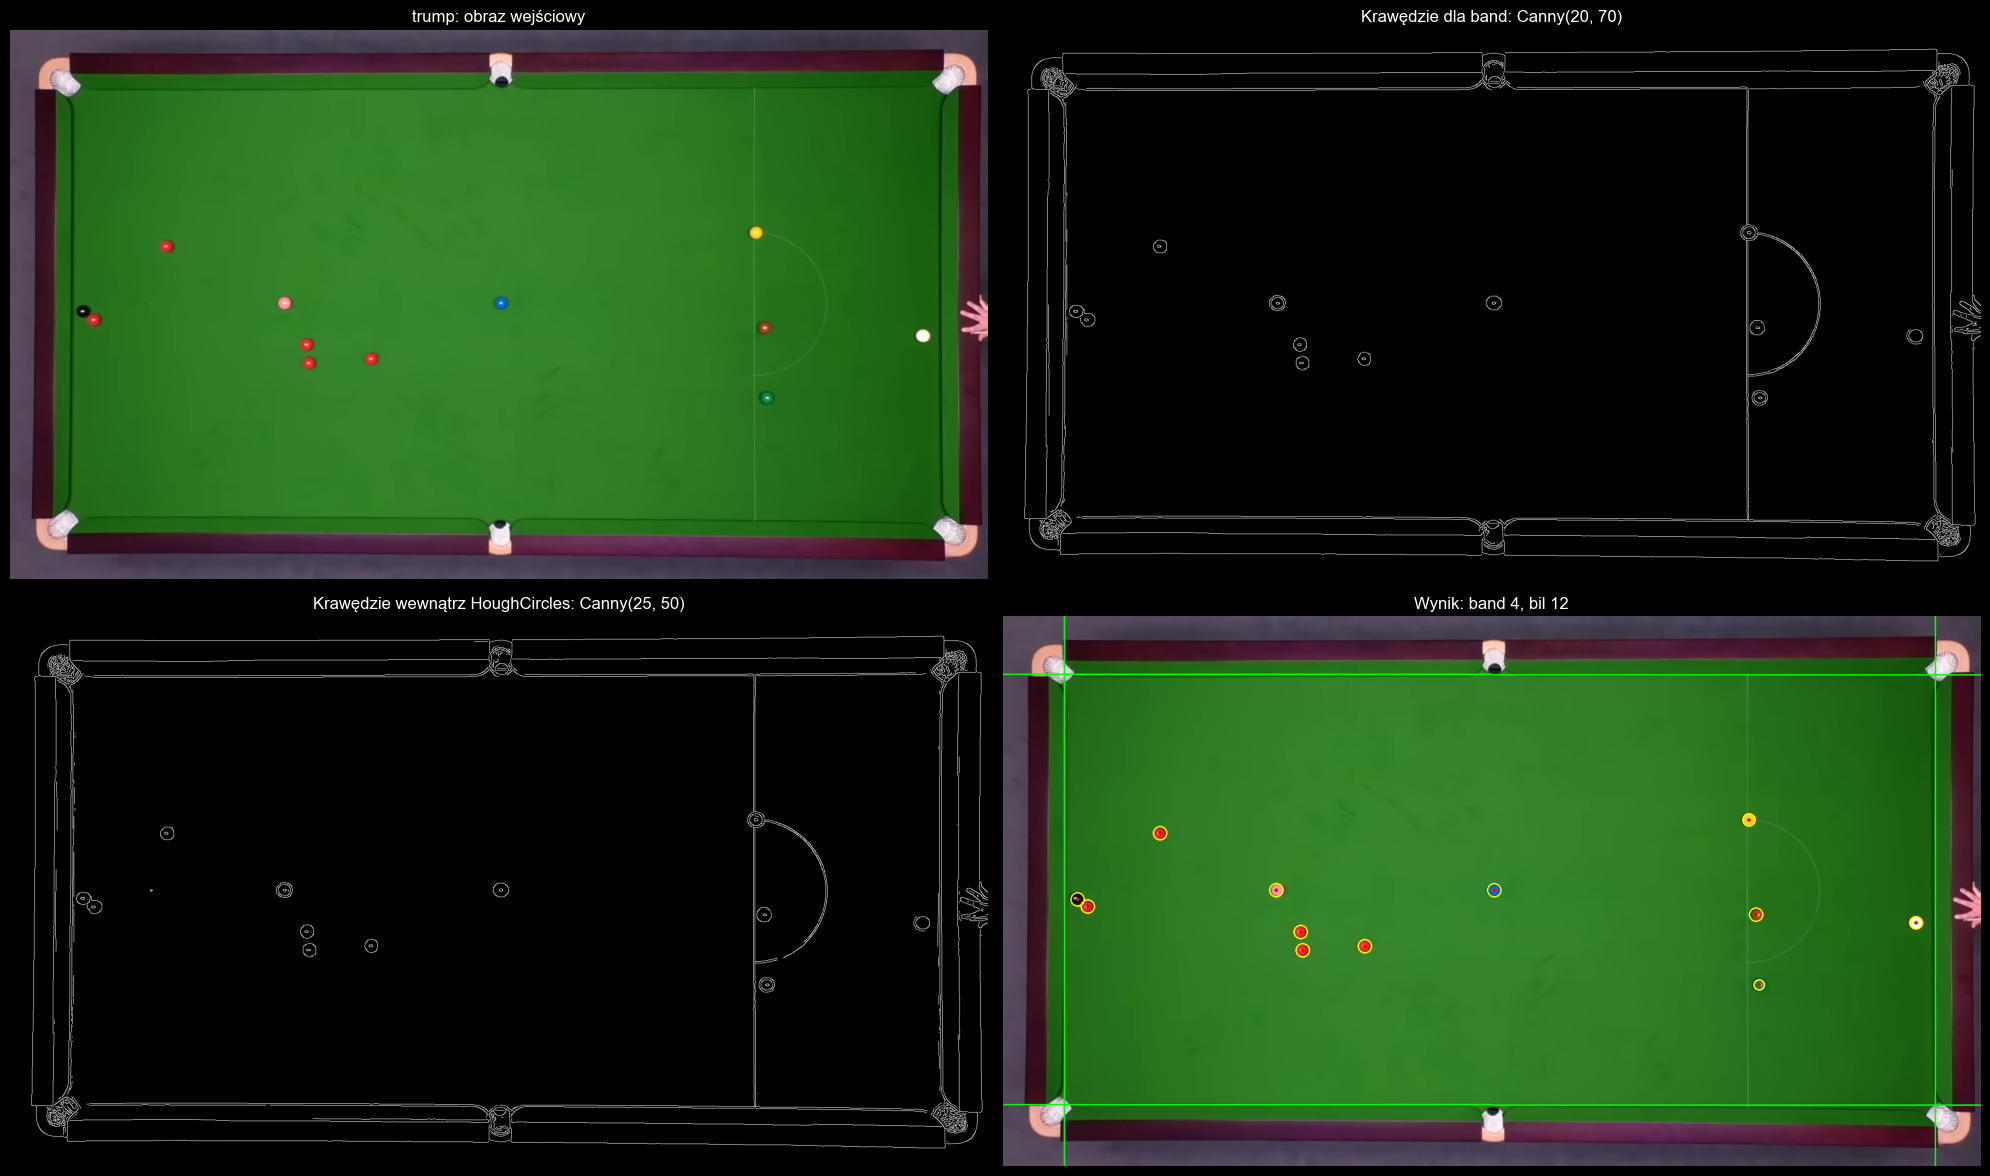

In [50]:
detections = {}
for img, name in [(zhao, 'zhao'), (mcgill2, 'mcgill2'), (mcgill, 'mcgill'), (trump, 'trump')]:
    detections[name] = show_pipeline(img, name)